# Genre Classification with Classic Machine Learning

Fuck all those cutting edge techniques with transformers and LLM's I'm taking this bitch back to the stone age. This is a throwback to simpler times when NVIDIA was only known by nerds and a GPU was only used by gamers.
This notebook predicts a song's genre from averaged GloVe vectors and asks whether adding TF-IDF word weights helps. The same four classic models are trained on two feature sets and compared on the same validation songs and then the best two are used for further experiments:

- **Feature sets:** `GloVe` (25 averaged embedding dimensions) and `GloVe + TF-IDF` (the same 25 dimensions plus 1000 TF-IDF columns), both created in `preprocessing_unified.ipynb`.
- **Models:** histogram gradient boosting, random forest, Gaussian naive Bayes and logistic regression.
- **Evaluation:** every run is analysed with `diagnose` from `utils/funcs.py` (scores, confusion matrix, scores per genre, predicted vs true genre share, ROC curves), followed by a direct comparison of the two feature sets.
- **Validation split:** the rows of the feature files follow `data/splits.parquet`, the shared stratified 25% split, so the results are comparable with the transformer models of the project.

## Setup

In [94]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.multiclass import OneVsRestClassifier
from sklearn.multioutput import ClassifierChain

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:
SEED = 80085      # ;)

BALANCED = True   # True: class weights in the training loss (no resampling), False: plain loss
TRAIN = False    # False: load the saved predictions instead of training

In [ ]:
# The project root, which holds data/ and models/. Adjusted if the notebook is run from a subfolder
project_dir = Path(".")
if not (project_dir / "data").exists() and (Path("..") / "data").exists():
    project_dir = Path("..")
sys.path.append(str(project_dir.resolve()))   # for the shared utils package

from utils.funcs import (diagnose, diagnose_runs, compare, make_models, make_forest, make_hgb, forest_oob,
                         fit_run, save_runs, load_runs, hyperband, plot_hyperband)

data_dir = project_dir / "data"
glove_dir = data_dir / "data-GloVe"
classic_dir = data_dir / "data-Classic"

## Loading the Data

Commitment has never been my strong suit, so instead of picking one dataset I took both: the averaged GloVe vectors (`data-GloVe`) and the GloVe vectors combined with TF-IDF features (`data-Classic`). Both were created from the same songs in the same order, which is checked here: the row counts must match the `train` and `val` assignment in `data/splits.parquet`, and the genre labels of both files must be identical.

The test set is not needed for the model comparison. It is only loaded at the end of the notebook, for the submission.

In [98]:
splits = pl.read_parquet(data_dir / "splits.parquet")
n_train = splits.filter(pl.col("split") == "train").height
n_val = splits.filter(pl.col("split") == "val").height

glove_train = pl.read_csv(glove_dir / "train_glove.csv")
glove_val = pl.read_csv(glove_dir / "val_glove.csv")
both_train = pl.read_parquet(classic_dir / "train_glove_tfidf.parquet")
both_val = pl.read_parquet(classic_dir / "val_glove_tfidf.parquet")

assert glove_train.height == both_train.height == n_train, "train rows differ from splits.parquet"
assert glove_val.height == both_val.height == n_val, "validation rows differ from splits.parquet"
assert (glove_train["genre"] == both_train["genre"]).all(), "train labels differ between the two datasets"
assert (glove_val["genre"] == both_val["genre"]).all(), "validation labels differ between the two datasets"

print(f"train: {n_train:,}  validation: {n_val:,}")
print(f"GloVe: {glove_train.width - 1} features, GloVe + TF-IDF: {both_train.width - 1} features")

train: 100,893  validation: 33,632
GloVe: 25 features, GloVe + TF-IDF: 1025 features


The genres are used as text labels. Their distribution in the training and validation set is almost identical, since the split is stratified. The share of the biggest genre is the accuracy of a model that always guesses it, which every model has to beat. Because the genres are very imbalanced, **macro F1** (every genre counts equally) is the main metric, next to accuracy.

In [99]:
y_train = glove_train["genre"].to_numpy()
y_val = glove_val["genre"].to_numpy()
genres = np.unique(y_train)

(glove_train.select("genre").to_series().value_counts(normalize=True).rename({"proportion": "train"})
    .join(glove_val.select("genre").to_series().value_counts(normalize=True).rename({"proportion": "validation"}), on="genre")
    .with_columns(pl.col("train", "validation").round(3))
    .sort("train", descending=True))

genre,train,validation
str,f64,f64
"""pop""",0.412,0.412
"""rap""",0.286,0.286
"""rock""",0.188,0.188
"""rb""",0.046,0.046
"""misc""",0.042,0.042
"""country""",0.026,0.026


## Feature Sets

Both feature sets are converted to float32 matrices:

- `glove`: the 25 dimensions `dim_0` to `dim_24`, the mean GloVe vector of the tokens of a song.
- `glove_tfidf`: the same 25 dimensions plus the TF-IDF weights of the 1000 most frequent terms. The TF-IDF vocabulary was fitted on the training songs only.

Since the TF-IDF columns are appended to the GloVe columns, the second feature set contains the first one, and any difference in the results comes from the TF-IDF features alone.

In [100]:
glove_cols = [c for c in glove_train.columns if c != "genre"]
both_cols = [c for c in both_train.columns if c != "genre"]
assert both_cols[:len(glove_cols)] == glove_cols, "the GloVe columns must come first"

feature_sets = {
    "glove": (glove_train.select(glove_cols).to_numpy().astype(np.float32),
              glove_val.select(glove_cols).to_numpy().astype(np.float32)),
    "glove_tfidf": (both_train.select(both_cols).to_numpy().astype(np.float32),
                    both_val.select(both_cols).to_numpy().astype(np.float32)),
}
feature_names = {"glove": glove_cols, "glove_tfidf": both_cols}
labels = {"glove": "GloVe", "glove_tfidf": "GloVe + TF-IDF"}

del glove_train, glove_val, both_train, both_val
for key, (X_tr, X_v) in feature_sets.items():
    print(f"{labels[key]:15} train {X_tr.shape}  validation {X_v.shape}")

GloVe           train (100893, 25)  validation (33632, 25)
GloVe + TF-IDF  train (100893, 1025)  validation (33632, 1025)


## Models

Four classic models are trained, each on both feature sets with identical settings:

- **Histogram gradient boosting** builds trees one after another, each correcting the errors of the previous ones, on binned features. It stops early when the score on 10% of the training data no longer improves, so it does not use the shared validation set for training decisions.
- **Random forest** averages 300 decorrelated trees. `min_samples_leaf=5` limits how closely single trees can memorise the training songs.
- **Gaussian naive Bayes** assumes that every feature is normally distributed within a genre and independent of the others. The multinomial variant cannot be used, because GloVe values can be negative. The skewed, sparse TF-IDF columns violate the normal assumption, so this model is expected to profit least from them.
- **Logistic regression** is a linear model, the regression baseline. The features are standardised first, because GloVe dimensions and TF-IDF weights live on very different scales, which would slow down and distort the optimisation.

**Class weights.** The genres are very imbalanced. With `BALANCED = True` the loss of the models is weighted by the inverse genre frequency (`"balanced"` weights of scikit-learn), the same idea as the weighted loss of the transformer notebook. The data itself is not resampled, and the validation set keeps its real distribution. Gaussian naive Bayes has no class weights and keeps its learned genre priors.

In [38]:
# the settings of the models are in make_models (utils/funcs.py), a fresh set for every feature set
list(make_models(SEED, BALANCED))

['HistGradientBoosting', 'RandomForest', 'NaiveBayes', 'LogisticRegression']

## Training

Every model is fitted on the training songs of each feature set (4 models × 2 feature sets = 8 runs). For every run the notebook keeps the validation probabilities, the training accuracy and the fit time, which is everything the evaluation needs. For the random forest, the feature importances of both feature sets are kept as well.

**Saving.** The results are written to `models/classic/` (`val_proba.npz`, `runs.json`), a few megabytes in total, instead of the fitted models, which can be several hundred megabytes for the random forests.

**Switch.** `TRAIN = False` skips the training and loads the saved results, so the evaluation can be run again without refitting anything.

In [ ]:
if TRAIN:
    runs, importances = {}, {}
    for fs, (X_tr, X_v) in feature_sets.items():
        for m, model in make_models(SEED, BALANCED).items():
            runs[(fs, m)] = fit_run(model, X_tr, y_train, X_v, genres, name=f"{labels[fs]} | {m}")
            if m == "RandomForest":
                importances[fs] = model.feature_importances_
    save_runs(runs, classic_dir / "val_proba.npz", classic_dir / "runs.json", importances)
else:
    runs, importances = load_runs(classic_dir / "val_proba.npz", classic_dir / "runs.json")

## Evaluation

Every run is analysed with `diagnose` (`utils/funcs.py`), which prints the headline scores and draws four plots for one classifier:

1. the **confusion matrix**, normalised per true genre, so the diagonal is the recall of each genre,
2. **precision, recall and F1 per genre**, with the number of validation songs,
3. the **true vs predicted share** of every genre, which shows whether a model over or under predicts the big genres,
4. one vs rest **ROC curves** with their AUC, and their macro average.

The headline scores report the validation accuracy next to the accuracy of always guessing the biggest genre, the training accuracy, macro F1 and weighted F1. `diagnose_runs` calls `diagnose` for every run of a dict of runs and titles it with the key of the run. The scores of all runs are put side by side by `compare` in the next section.

Each model is evaluated on both feature sets, `GloVe` first.

### Histogram Gradient Boosting

train accuracy: 0.515
val accuracy:   0.462  (always guessing the biggest genre: 0.412)
macro F1:       0.402
weighted F1:    0.474
              precision    recall  f1-score   support

     country       0.10      0.52      0.17       865
        misc       0.36      0.63      0.46      1398
         pop       0.66      0.21      0.32     13870
         rap       0.81      0.76      0.79      9632
          rb       0.15      0.54      0.24      1548
        rock       0.39      0.48      0.43      6319

    accuracy                           0.46     33632
   macro avg       0.41      0.53      0.40     33632
weighted avg       0.60      0.46      0.47     33632



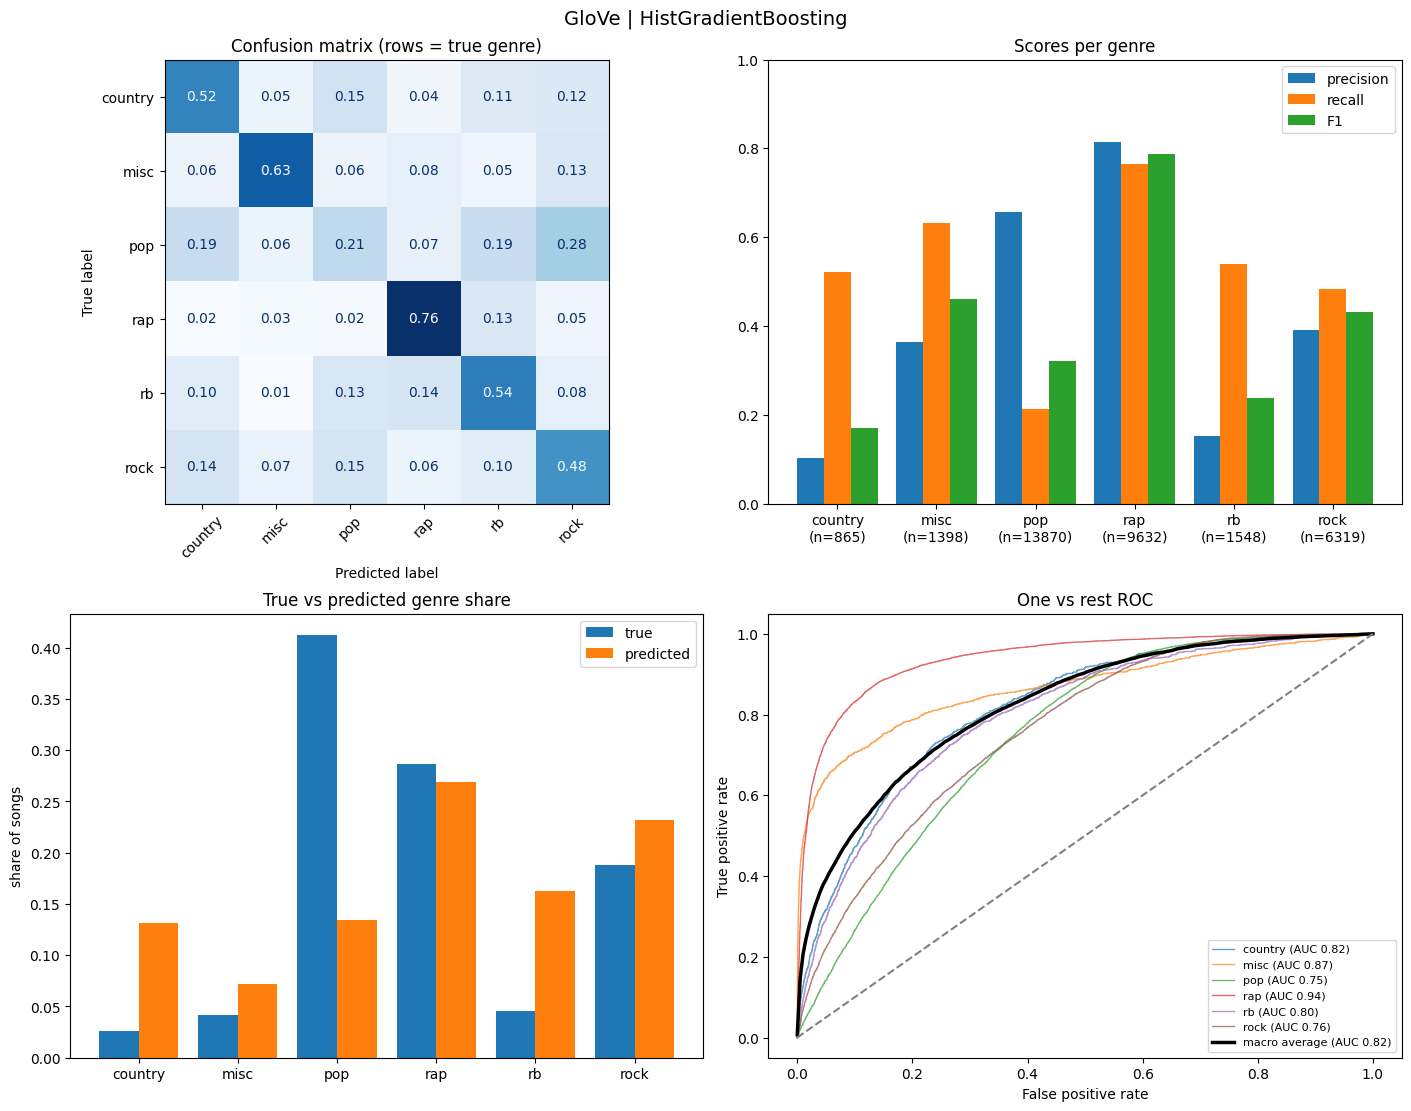

train accuracy: 0.600
val accuracy:   0.528  (always guessing the biggest genre: 0.412)
macro F1:       0.457
weighted F1:    0.543
              precision    recall  f1-score   support

     country       0.15      0.57      0.24       865
        misc       0.40      0.64      0.49      1398
         pop       0.66      0.32      0.43     13870
         rap       0.87      0.81      0.84      9632
          rb       0.19      0.53      0.28      1548
        rock       0.42      0.53      0.47      6319

    accuracy                           0.53     33632
   macro avg       0.45      0.57      0.46     33632
weighted avg       0.63      0.53      0.54     33632



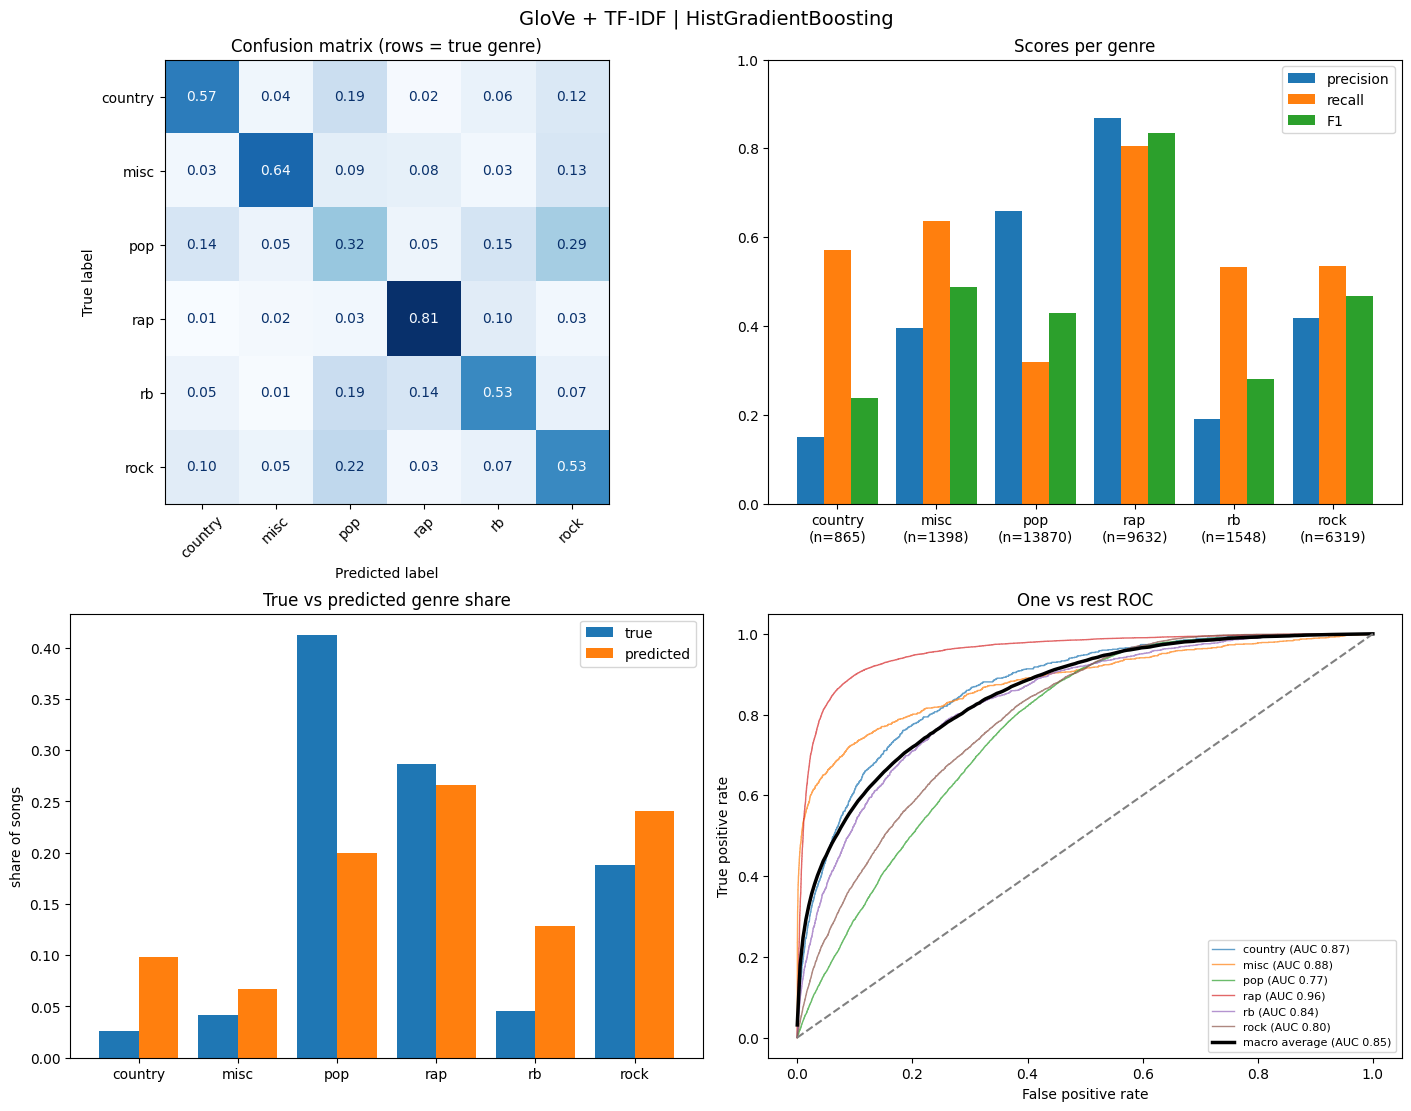

In [43]:
diagnose_runs(y_val, {k: r for k, r in runs.items() if k[1] == "HistGradientBoosting"}, genres, labels)

### Random Forest

train accuracy: 0.923
val accuracy:   0.619  (always guessing the biggest genre: 0.412)
macro F1:       0.445
weighted F1:    0.600
              precision    recall  f1-score   support

     country       0.26      0.06      0.10       865
        misc       0.54      0.56      0.55      1398
         pop       0.60      0.70      0.65     13870
         rap       0.77      0.84      0.80      9632
          rb       0.27      0.16      0.20      1548
        rock       0.44      0.32      0.37      6319

    accuracy                           0.62     33632
   macro avg       0.48      0.44      0.44     33632
weighted avg       0.59      0.62      0.60     33632



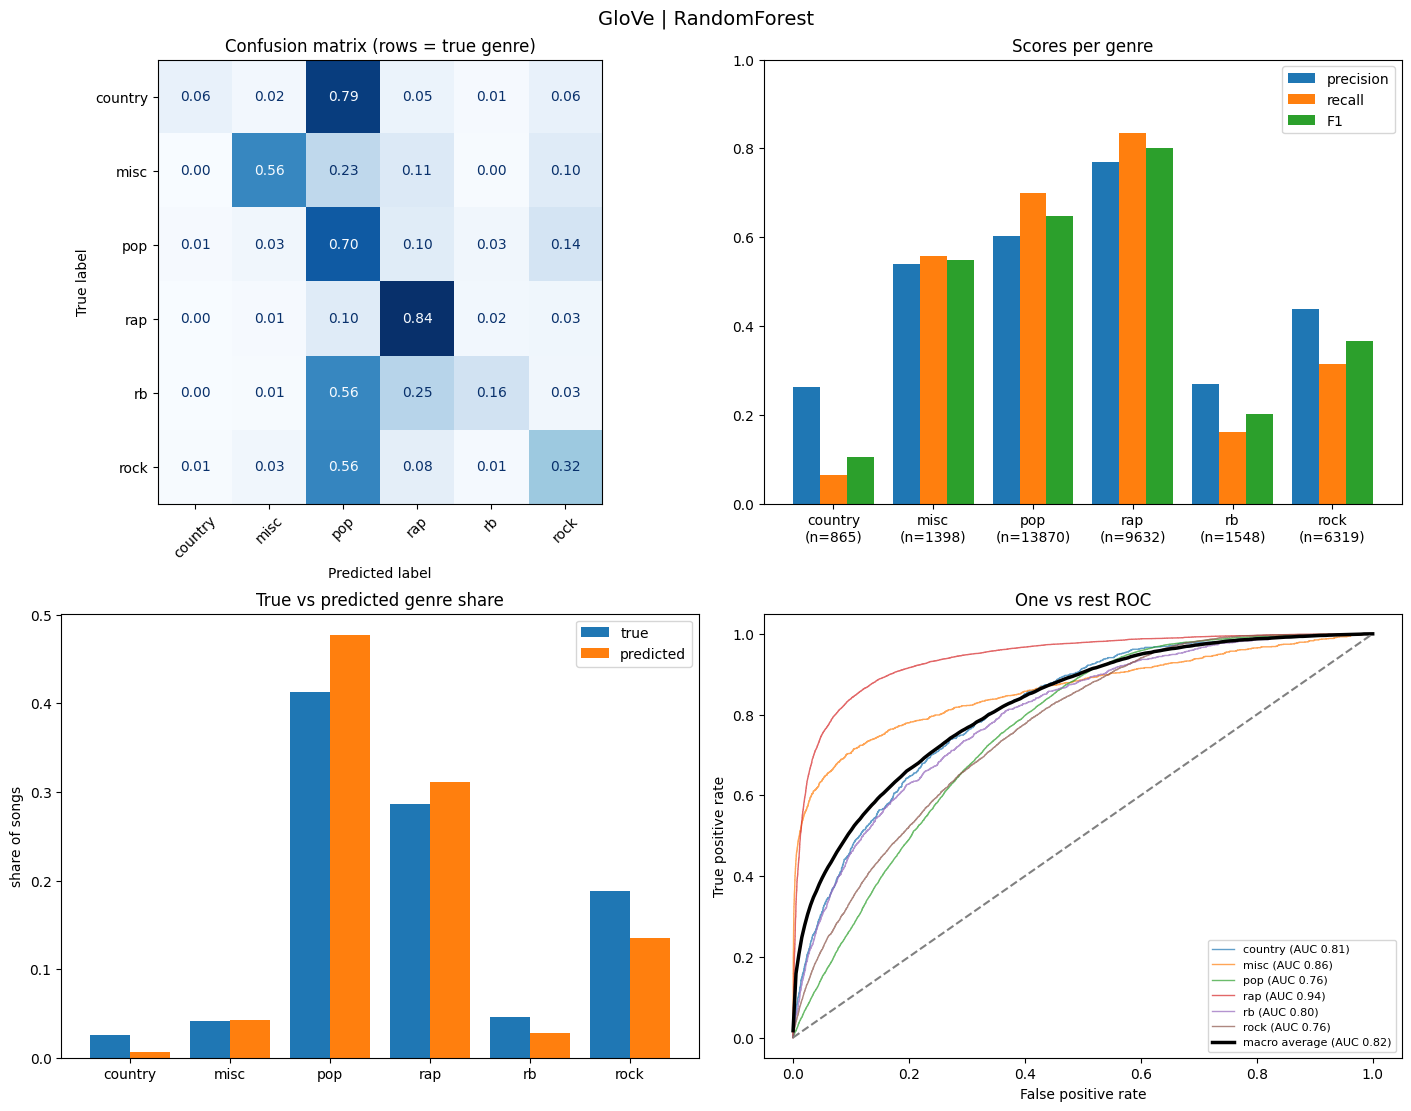

train accuracy: 0.913
val accuracy:   0.629  (always guessing the biggest genre: 0.412)
macro F1:       0.452
weighted F1:    0.613
              precision    recall  f1-score   support

     country       0.29      0.03      0.05       865
        misc       0.53      0.57      0.55      1398
         pop       0.61      0.69      0.65     13870
         rap       0.80      0.85      0.82      9632
          rb       0.30      0.20      0.24      1548
        rock       0.45      0.35      0.39      6319

    accuracy                           0.63     33632
   macro avg       0.50      0.45      0.45     33632
weighted avg       0.61      0.63      0.61     33632



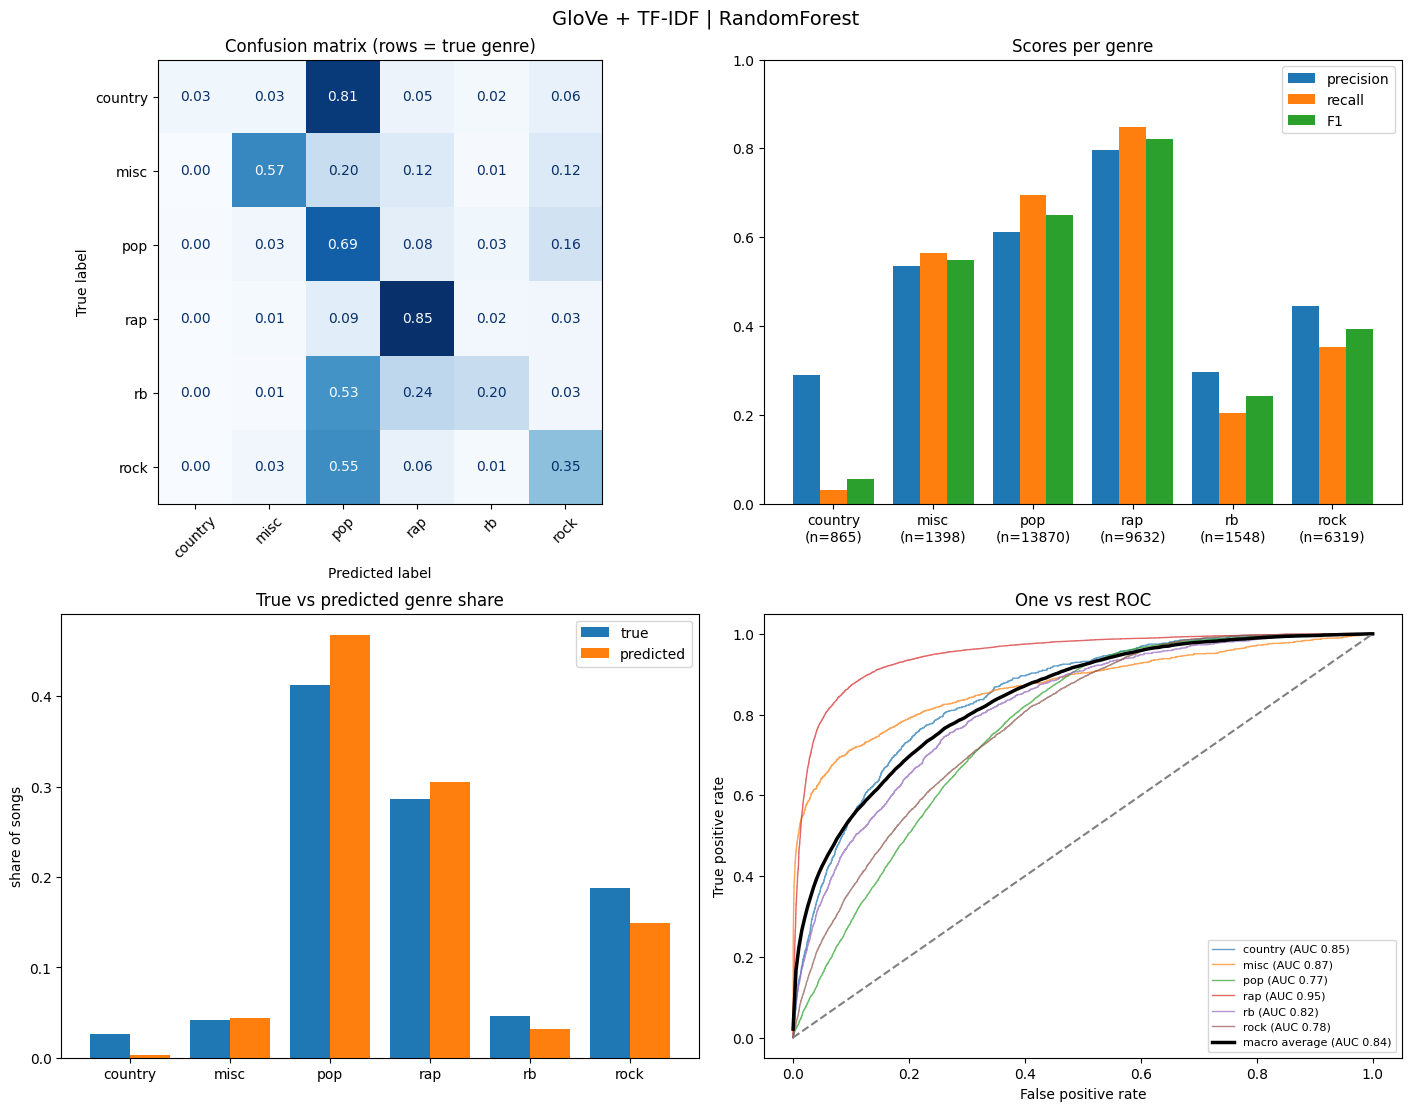

In [41]:
diagnose_runs(y_val, {k: r for k, r in runs.items() if k[1] == "RandomForest"}, genres, labels)

### Gaussian Naive Bayes

train accuracy: 0.378
val accuracy:   0.379  (always guessing the biggest genre: 0.412)
macro F1:       0.299
weighted F1:    0.403
              precision    recall  f1-score   support

     country       0.14      0.05      0.08       865
        misc       0.19      0.62      0.29      1398
         pop       0.58      0.24      0.34     13870
         rap       0.71      0.65      0.68      9632
          rb       0.09      0.64      0.16      1548
        rock       0.35      0.19      0.24      6319

    accuracy                           0.38     33632
   macro avg       0.34      0.40      0.30     33632
weighted avg       0.52      0.38      0.40     33632



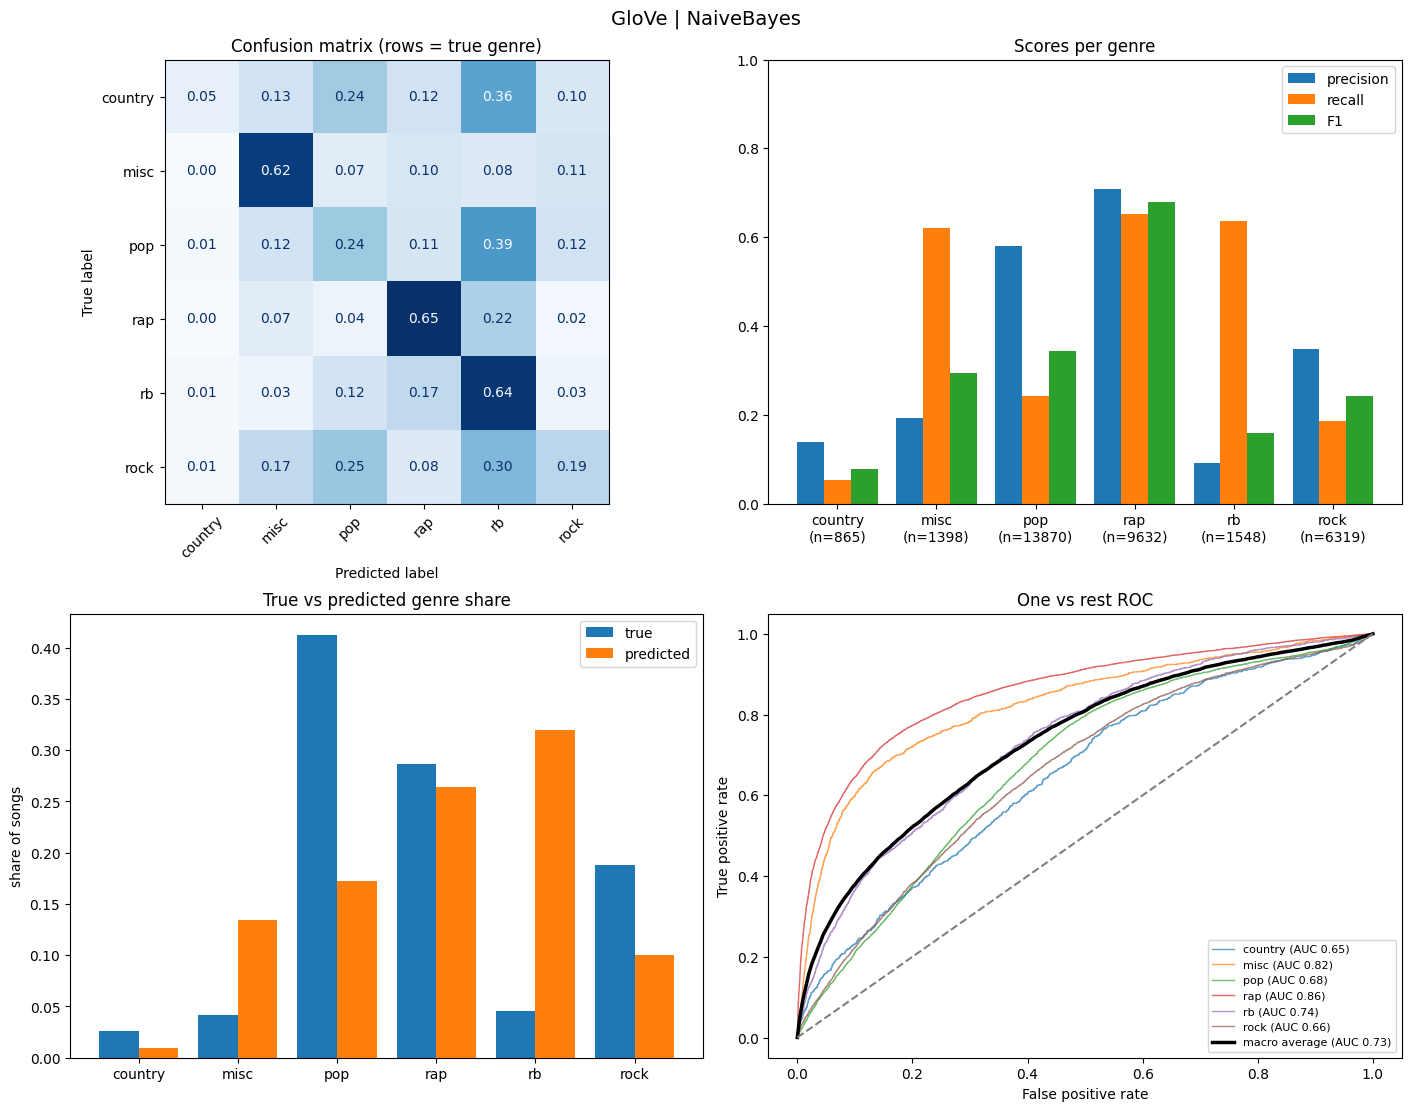

train accuracy: 0.390
val accuracy:   0.383  (always guessing the biggest genre: 0.412)
macro F1:       0.339
weighted F1:    0.370
              precision    recall  f1-score   support

     country       0.07      0.70      0.13       865
        misc       0.29      0.59      0.39      1398
         pop       0.58      0.06      0.10     13870
         rap       0.80      0.74      0.77      9632
          rb       0.16      0.43      0.23      1548
        rock       0.38      0.46      0.42      6319

    accuracy                           0.38     33632
   macro avg       0.38      0.50      0.34     33632
weighted avg       0.56      0.38      0.37     33632



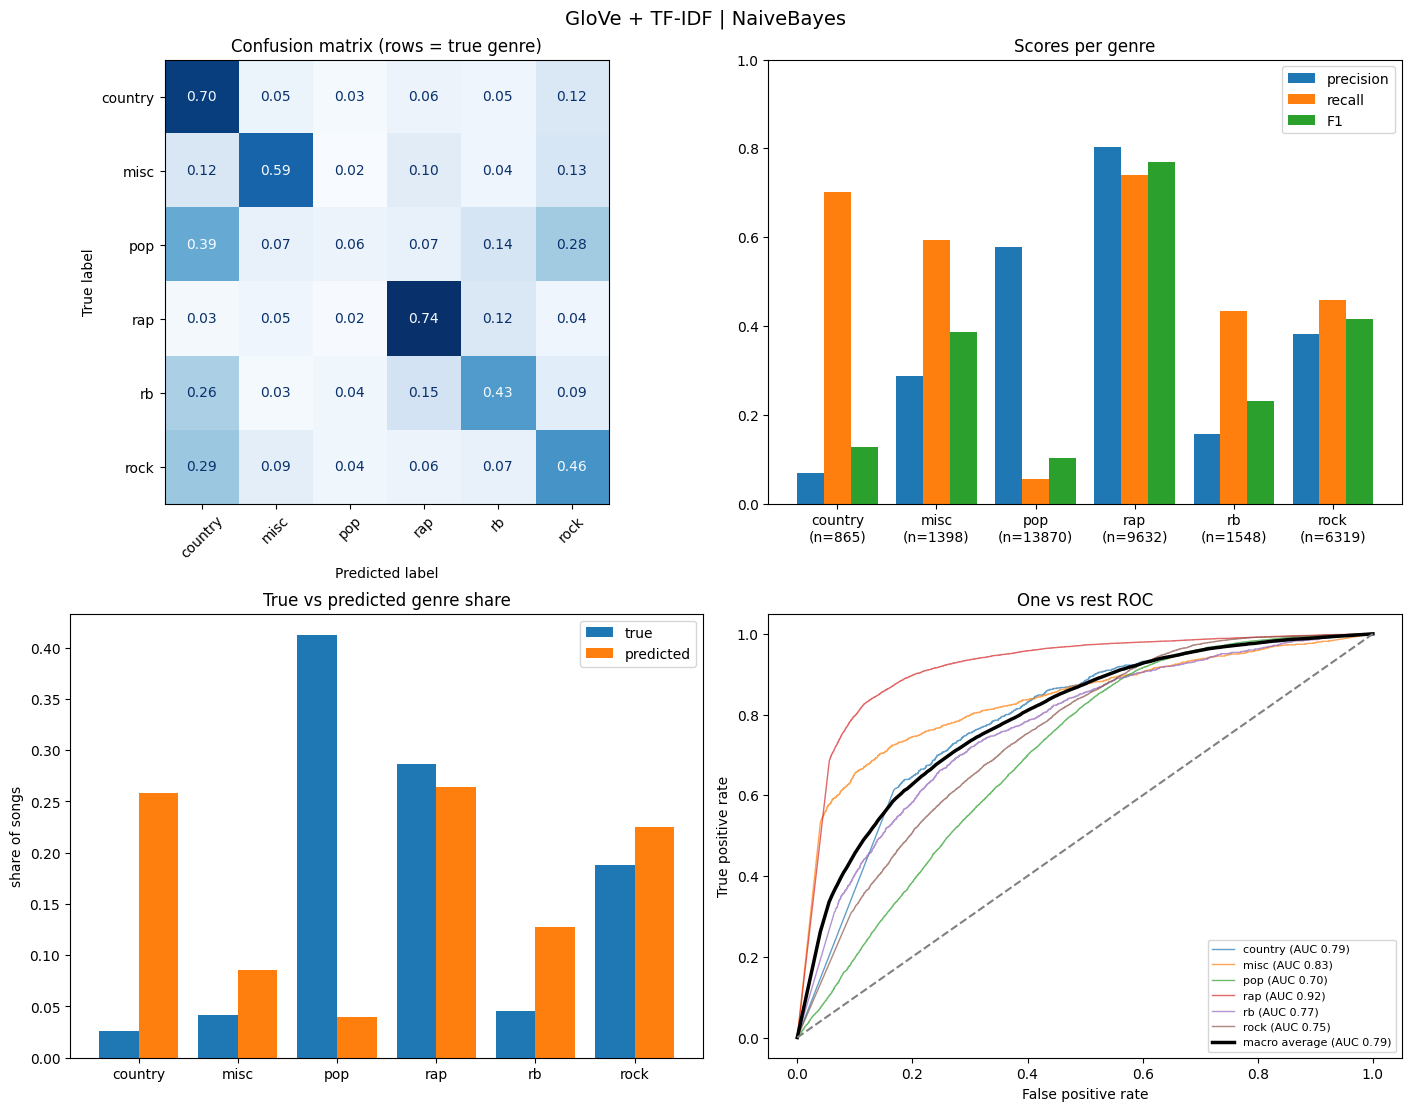

In [44]:
diagnose_runs(y_val, {k: r for k, r in runs.items() if k[1] == "NaiveBayes"}, genres, labels)

### Logistic Regression

train accuracy: 0.425
val accuracy:   0.426  (always guessing the biggest genre: 0.412)
macro F1:       0.371
weighted F1:    0.435
              precision    recall  f1-score   support

     country       0.10      0.58      0.16       865
        misc       0.27      0.65      0.38      1398
         pop       0.63      0.16      0.25     13870
         rap       0.83      0.73      0.78      9632
          rb       0.15      0.55      0.23      1548
        rock       0.39      0.45      0.42      6319

    accuracy                           0.43     33632
   macro avg       0.39      0.52      0.37     33632
weighted avg       0.59      0.43      0.43     33632



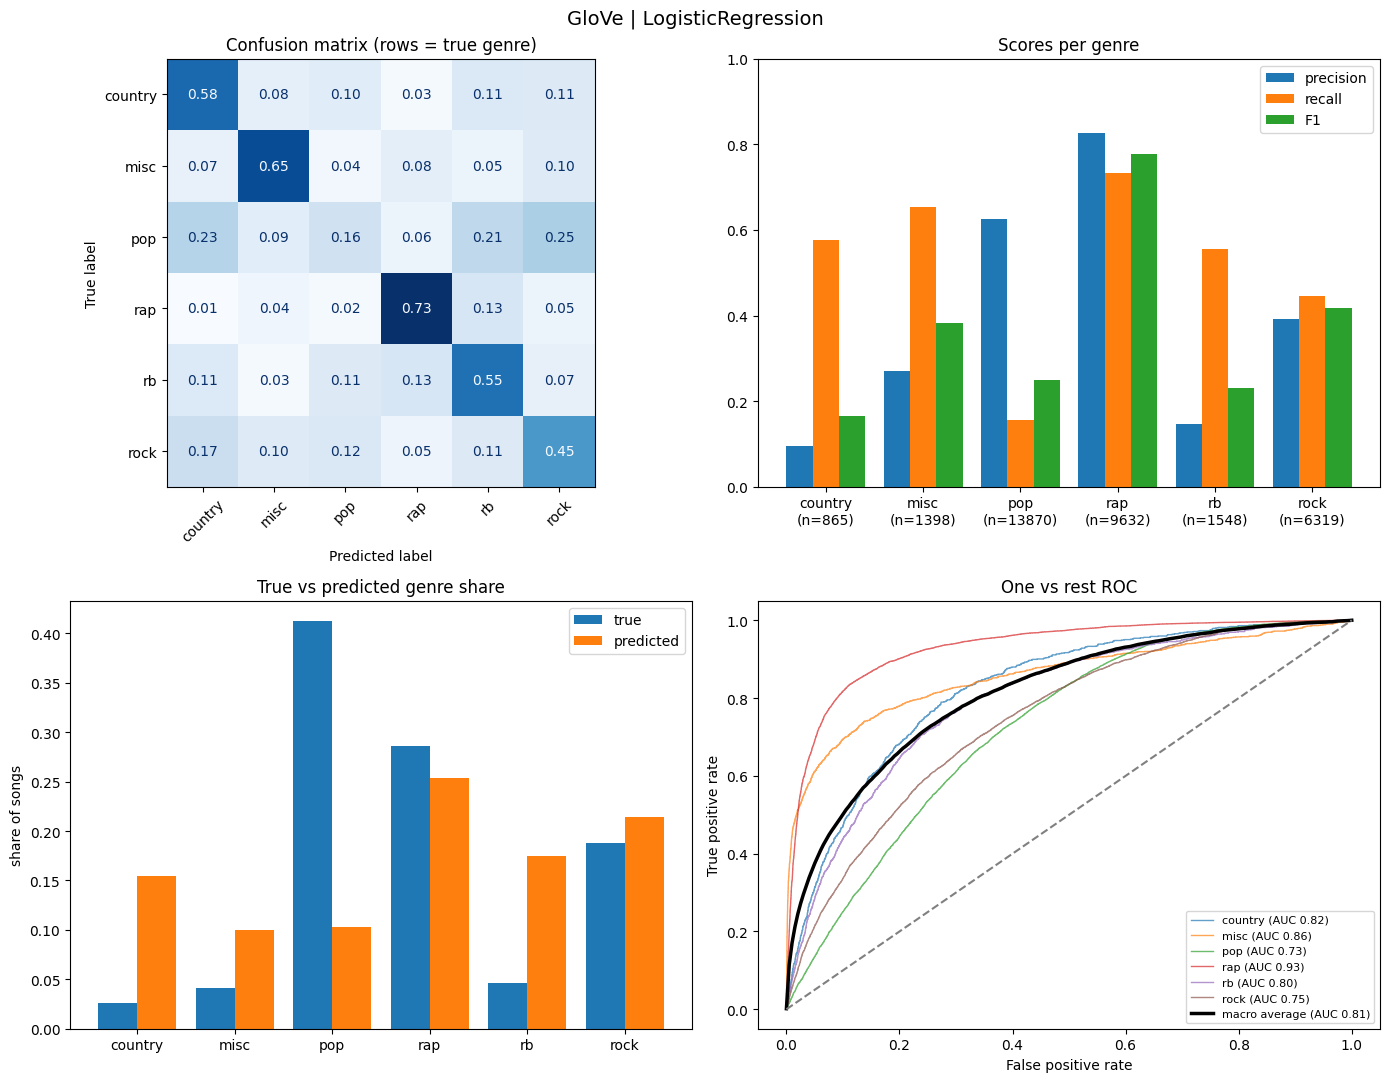

train accuracy: 0.512
val accuracy:   0.492  (always guessing the biggest genre: 0.412)
macro F1:       0.425
weighted F1:    0.509
              precision    recall  f1-score   support

     country       0.13      0.64      0.21       865
        misc       0.30      0.65      0.41      1398
         pop       0.67      0.25      0.37     13870
         rap       0.88      0.77      0.82      9632
          rb       0.18      0.55      0.27      1548
        rock       0.42      0.52      0.46      6319

    accuracy                           0.49     33632
   macro avg       0.43      0.56      0.42     33632
weighted avg       0.63      0.49      0.51     33632



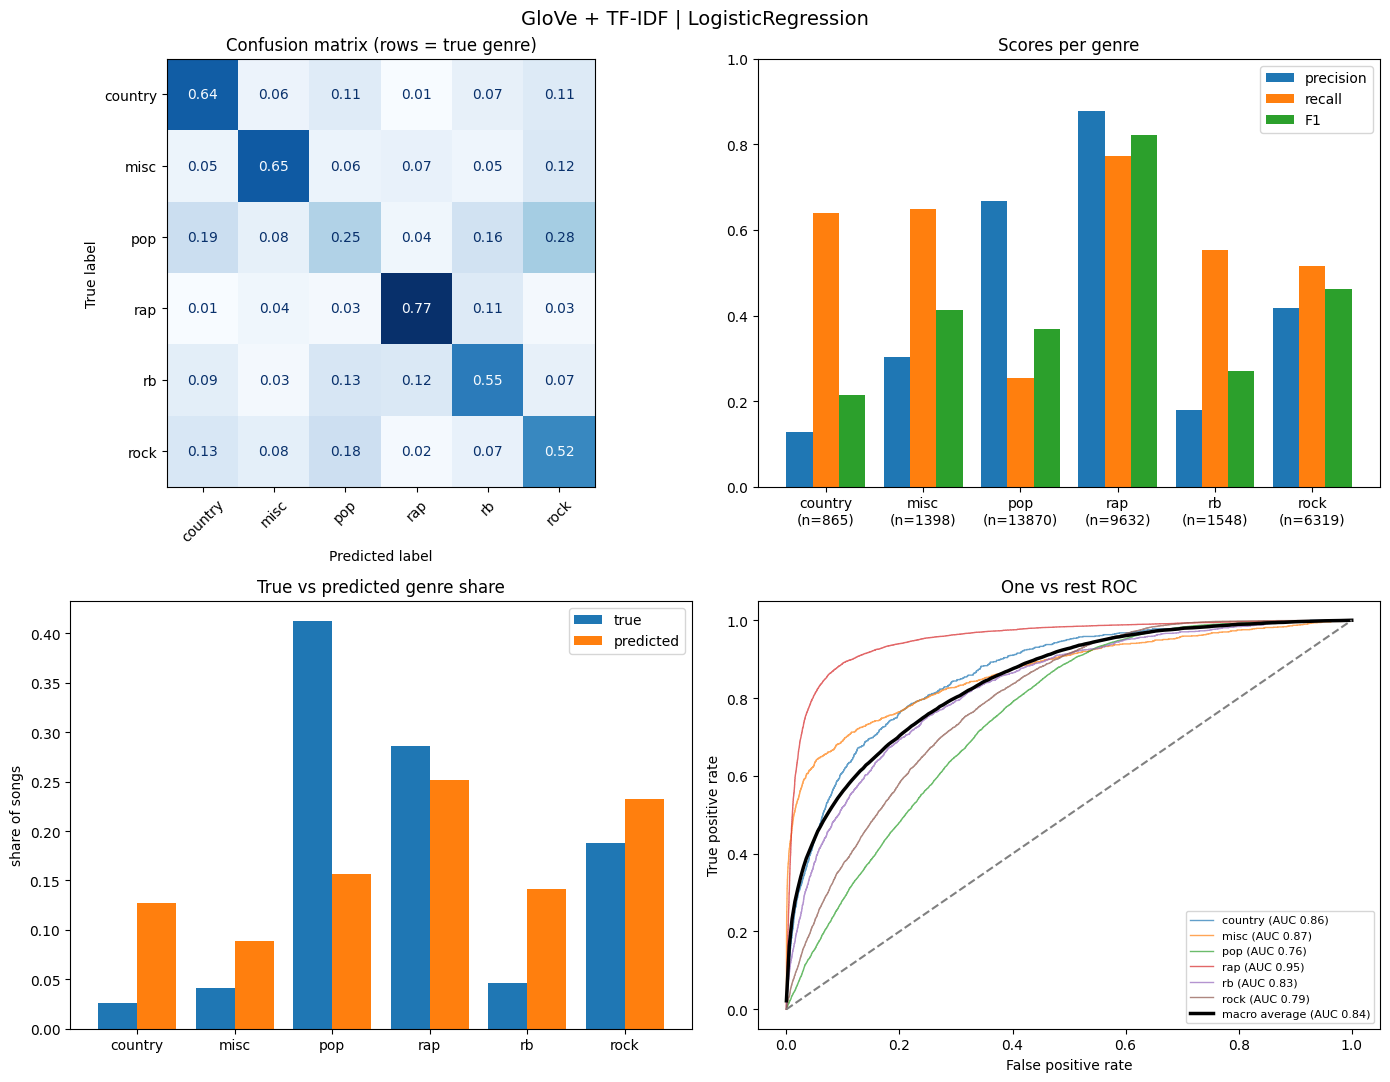

In [76]:
diagnose_runs(y_val, {k: r for k, r in runs.items() if k[1] == "LogisticRegression"}, genres, labels)

The pecking order is already visible from the four sections above: the two tree ensembles, random forest and histogram gradient boosting, leave naive Bayes and logistic regression in the dust. Time to put all eight runs next to each other and see how much TF-IDF actually adds.

## Comparison of the Feature Sets

`compare` (`utils/funcs.py`) puts all eight runs side by side, like `diagnose` does for one run: a table with the scores sorted by macro F1, a table with the F1 per genre, and a head to head chart of `GloVe` against `GloVe + TF-IDF` for every model, in the order of the models. The outlined bar wins, and the box on top is the change from adding TF-IDF (▲ better, ▼ worse). The dashed line is the accuracy of always guessing the biggest genre. The table after the chart lists the same gains per model.

features,model,train_accuracy,accuracy,macro_f1,weighted_f1,fit_seconds
str,str,f64,f64,f64,f64,f64
"""GloVe + TF-IDF""","""HistGradientBoosting""",0.6,0.528,0.457,0.543,265.9
"""GloVe + TF-IDF""","""RandomForest""",0.913,0.629,0.452,0.613,84.6
"""GloVe""","""RandomForest""",0.923,0.619,0.445,0.6,43.3
"""GloVe + TF-IDF""","""LogisticRegression""",0.512,0.492,0.425,0.509,466.3
"""GloVe""","""HistGradientBoosting""",0.515,0.462,0.402,0.474,10.5
"""GloVe""","""LogisticRegression""",0.425,0.426,0.371,0.435,9.9
"""GloVe + TF-IDF""","""NaiveBayes""",0.39,0.383,0.339,0.37,2.3
"""GloVe""","""NaiveBayes""",0.378,0.379,0.299,0.403,0.4


features,model,country,misc,pop,rap,rb,rock
str,str,f64,f64,f64,f64,f64,f64
"""GloVe + TF-IDF""","""HistGradientBoosting""",0.237,0.488,0.429,0.835,0.281,0.468
"""GloVe + TF-IDF""","""RandomForest""",0.054,0.55,0.65,0.822,0.242,0.394
"""GloVe""","""RandomForest""",0.104,0.548,0.648,0.801,0.202,0.367
"""GloVe + TF-IDF""","""LogisticRegression""",0.214,0.413,0.368,0.822,0.271,0.461
"""GloVe""","""HistGradientBoosting""",0.171,0.462,0.321,0.788,0.238,0.432
"""GloVe""","""LogisticRegression""",0.165,0.383,0.25,0.777,0.232,0.418
"""GloVe + TF-IDF""","""NaiveBayes""",0.127,0.387,0.102,0.769,0.23,0.416
"""GloVe""","""NaiveBayes""",0.077,0.294,0.343,0.68,0.16,0.242


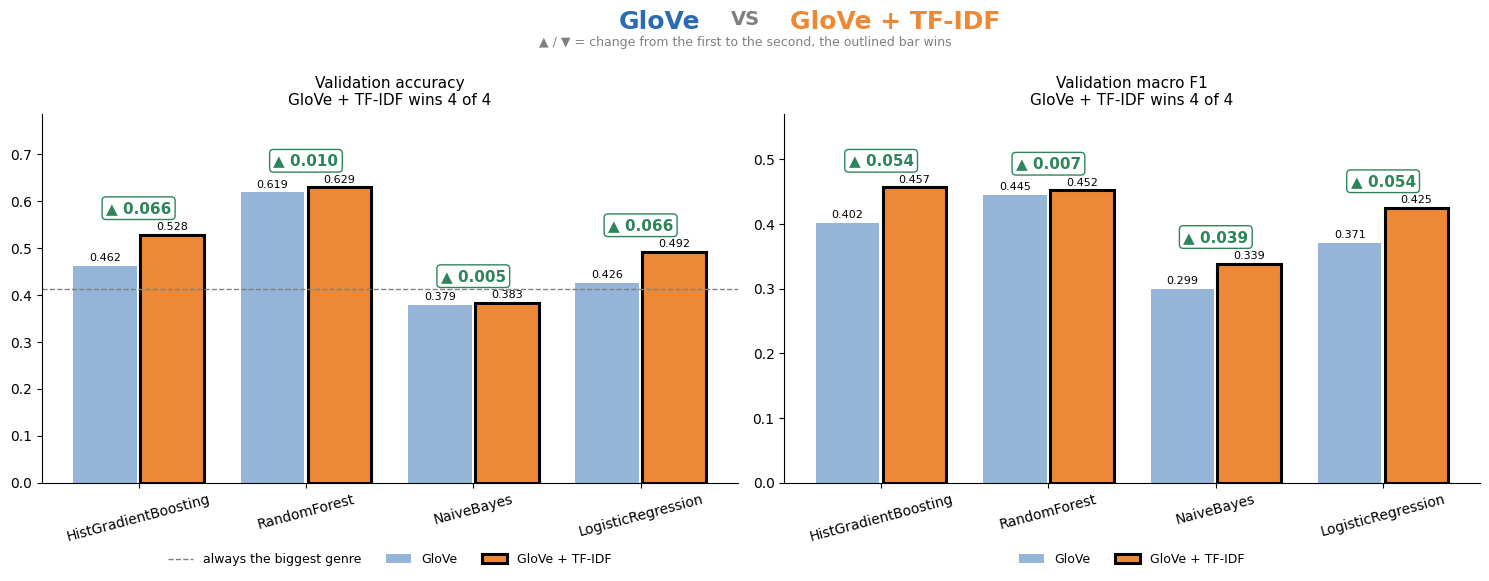

In [30]:
scores, f1 = compare(y_val, runs, genres, labels, key_names=("features", "model"))

In [31]:
glove, both = (scores.filter(pl.col("features") == labels[fs]).sort("model") for fs in ("glove", "glove_tfidf"))

pl.DataFrame({"model": glove["model"],
              "accuracy_glove": glove["accuracy"], "macro_f1_glove": glove["macro_f1"],
              "accuracy_tfidf": both["accuracy"], "macro_f1_tfidf": both["macro_f1"],
              "accuracy_gain": both["accuracy"] - glove["accuracy"],
              "macro_f1_gain": both["macro_f1"] - glove["macro_f1"]}).with_columns(pl.col(pl.Float64).round(3))

model,accuracy_glove,macro_f1_glove,accuracy_tfidf,macro_f1_tfidf,accuracy_gain,macro_f1_gain
str,f64,f64,f64,f64,f64,f64
"""HistGradientBoosting""",0.462,0.402,0.528,0.457,0.066,0.054
"""LogisticRegression""",0.426,0.371,0.492,0.425,0.066,0.054
"""NaiveBayes""",0.379,0.299,0.383,0.339,0.005,0.039
"""RandomForest""",0.619,0.445,0.629,0.452,0.01,0.007


The verdict: naive Bayes is trash. It does even worse than the laziest model imaginable, the one that just yells "pop" at every song (0.38 vs 0.41 accuracy). Logistic regression is nothing to write home about either, but the tree ensembles play in a different league. Gradient boosting edges out the random forest by a hair in macro F1 (0.457 vs 0.452), and, tied with logistic regression, it also gets the biggest boost (pun intended) from TF-IDF: +5.5 points of macro F1.

Still, the random forest becomes my main test subject for now. It is almost as good, trains in about a third of the time (85 s vs 266 s), and my laptop ain't built for all that. Gradient boosting gets its moment later on, once the forest has gone through all the experiments.

### Which Genres Profit from TF-IDF?

The change in F1 per genre when TF-IDF is added to the GloVe vectors (blue: TF-IDF better, red: GloVe alone better). A model can gain on average, while still getting worse on single genres, which the overall scores hide.

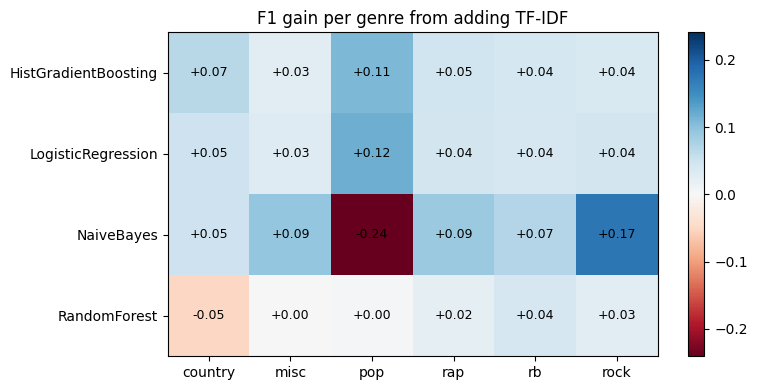

In [32]:
f1_glove, f1_both = (f1.filter(pl.col("features") == labels[fs]).sort("model") for fs in ("glove", "glove_tfidf"))
gain = f1_both.select(list(genres)).to_numpy() - f1_glove.select(list(genres)).to_numpy()
limit = max(abs(gain).max(), 0.05)

fig, ax = plt.subplots(figsize=(8, 4))
image = ax.imshow(gain, cmap="RdBu", vmin=-limit, vmax=limit, aspect="auto")
ax.set_xticks(range(len(genres)), genres)
ax.set_yticks(range(len(gain)), f1_glove["model"])
for i in range(gain.shape[0]):
    for j in range(gain.shape[1]):
        ax.text(j, i, f"{gain[i, j]:+.2f}", ha="center", va="center", fontsize=9)
ax.set_title("F1 gain per genre from adding TF-IDF")
fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()

## Which Features Does the Random Forest Use?

The impurity based feature importances of the random forest trained on `GloVe + TF-IDF`, as a look at what the model relies on. If the 1000 TF-IDF columns (97.6% of the features) carry only a small share of the importance, the 25 GloVe dimensions do most of the work, and the gain from TF-IDF is expected to be small. Impurity importances favour features with many distinct values, so they are a rough guide, not a proof.

TF-IDF columns: 97.6% of the features, 55.8% of the importance
GloVe columns:  2.4% of the features, 44.2% of the importance


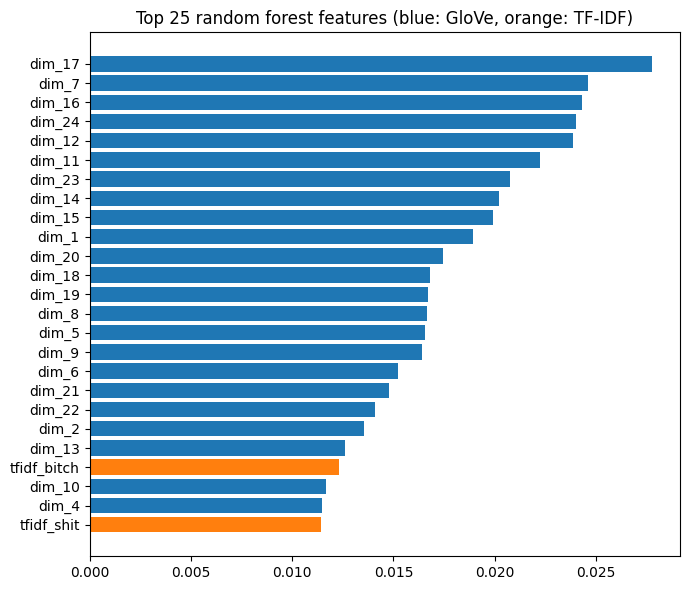

In [33]:
importance = importances["glove_tfidf"]
names = np.array(feature_names["glove_tfidf"])
is_tfidf = np.char.startswith(names, "tfidf_")

print(f"TF-IDF columns: {is_tfidf.mean():.1%} of the features, {importance[is_tfidf].sum() / importance.sum():.1%} of the importance")
print(f"GloVe columns:  {(~is_tfidf).mean():.1%} of the features, {importance[~is_tfidf].sum() / importance.sum():.1%} of the importance")

top = np.argsort(importance)[::-1][:25][::-1]
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(names[top], importance[top], color=["tab:orange" if is_tfidf[i] else "tab:blue" for i in top])
ax.set_title("Top 25 random forest features (blue: GloVe, orange: TF-IDF)")
plt.tight_layout()
plt.show()

Taken together, the 1000 TF-IDF columns carry 55.8% of the importance, but every single one of them carries very little, so 23 of the top 25 spots go to GloVe dimensions. The only two words that make the cut are "bitch" and "shit", which, to be fair, are also the two most useful words in my daily vocabulary.

## Reading the Results

- **Accuracy vs macro F1.** A model that mostly predicts the big genres can reach a decent accuracy and still ignore the small ones. The comparison is therefore based on macro F1, and the accuracy only counts if it is clearly above the biggest genre baseline.
- **Training vs validation accuracy.** A random forest with a training accuracy close to 1 and a much lower validation accuracy memorises the training songs. A gap that is larger with TF-IDF than without it means the extra columns mainly gave the model more to overfit.
- **The effect of TF-IDF.** The gain tables and the per genre heatmap show where the 1000 extra word weights help. Averaged GloVe vectors blur which words a song contains, TF-IDF keeps the most frequent terms explicitly, so a gain is most likely for genres with a distinctive vocabulary.
- **Linear vs tree models.** Logistic regression shows how much of the signal a linear boundary captures. If the tree models are clearly better, the relation between the features and the genre is not linear.

## Random Forest: One-vs-Rest and Classifier Chain

The random forest above is a single multiclass model. Here the same forest is used in two other ways, both on the `GloVe + TF-IDF` features (the 1000 most frequent terms), to see whether splitting the six-genre problem into binary problems helps:

- **One-vs-rest.** One binary forest per genre (*is it rap or not?*), trained independently. The genre with the highest score wins. Every forest can focus on one genre, which may help the small ones, but the six scores are not calibrated against each other.
- **Classifier chain.** Also one binary forest per genre, but the forests are trained in a fixed order and every forest gets the answers for the genres before it as extra features. This lets the model use the relations between genres (*not country, not rb, so probably pop*). The genres are ordered from rarest to most frequent, so the big, diffuse genres are decided last with the most information. During training the true answers of the earlier genres are used, at prediction time the predicted ones, so a mistake early in the chain can carry over.

All forests use the settings of the random forest in `make_models`, including the class weights, which apply to the two classes of each binary problem. The plain multiclass forest is trained again here, so that all three runs use exactly the same settings. The binary probabilities of the chain are scaled to sum to one per song, which `diagnose` and the comparison need.

In [104]:
labels.update({"OneVsRest": "One-vs-rest", "Chain": "Classifier chain"})

X_tr, X_v = feature_sets["glove_tfidf"]

# one 0/1 column per genre, the target of the chain
Y_train = (y_train[:, None] == genres[None, :]).astype(int)
chain_order = np.argsort(Y_train.sum(axis=0))   # rarest genre first, the biggest genres last
print("chain order:", " -> ".join(genres[chain_order]))

rf = make_models(SEED, BALANCED)["RandomForest"]
multi_models = {"Multiclass": rf,
                "OneVsRest": OneVsRestClassifier(clone(rf)),
                "Chain": ClassifierChain(clone(rf), order=chain_order, random_state=SEED)}

multi_paths = (classic_dir / "ovr_chain_proba.npz", classic_dir / "ovr_chain_runs.json")
if TRAIN:
    multi_runs = {key: fit_run(model, X_tr, y_train, X_v, genres, name=key,
                               target=Y_train if key == "Chain" else None)
                  for key, model in multi_models.items()}
    save_runs(multi_runs, *multi_paths)
else:
    multi_runs, _ = load_runs(*multi_paths)

chain order: country -> misc -> rb -> rock -> rap -> pop
Multiclass                               fitted in   58.9s
OneVsRest                                fitted in  393.1s
Chain                                    fitted in  401.5s


### One-vs-Rest and Chain Evaluation

Both runs are analysed with `diagnose`, like the models above. The multiclass forest is only part of the comparison below.

train accuracy: 0.955
val accuracy:   0.658  (always guessing the biggest genre: 0.412)
macro F1:       0.423
weighted F1:    0.617
              precision    recall  f1-score   support

     country       0.29      0.00      0.00       865
        misc       0.73      0.50      0.59      1398
         pop       0.60      0.82      0.69     13870
         rap       0.80      0.87      0.83      9632
          rb       0.55      0.04      0.07      1548
        rock       0.52      0.25      0.34      6319

    accuracy                           0.66     33632
   macro avg       0.58      0.41      0.42     33632
weighted avg       0.64      0.66      0.62     33632



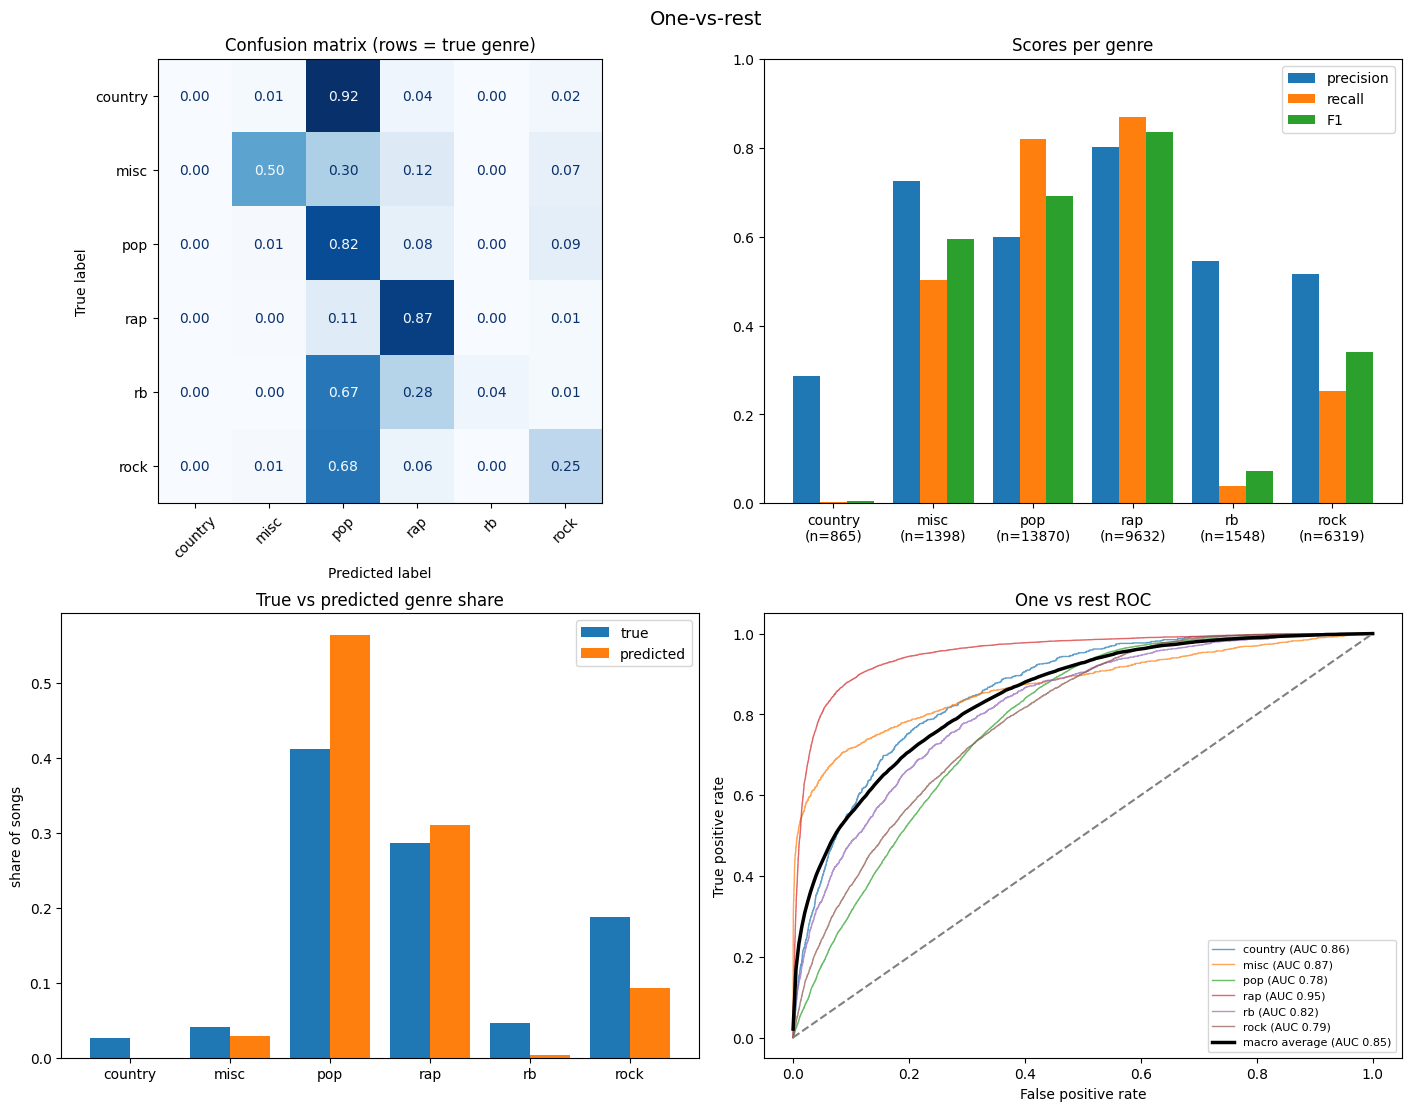

train accuracy: 0.940
val accuracy:   0.642  (always guessing the biggest genre: 0.412)
macro F1:       0.430
weighted F1:    0.616
              precision    recall  f1-score   support

     country       0.31      0.00      0.01       865
        misc       0.74      0.49      0.59      1398
         pop       0.59      0.75      0.66     13870
         rap       0.83      0.85      0.84      9632
          rb       0.53      0.04      0.08      1548
        rock       0.46      0.37      0.41      6319

    accuracy                           0.64     33632
   macro avg       0.58      0.42      0.43     33632
weighted avg       0.63      0.64      0.62     33632



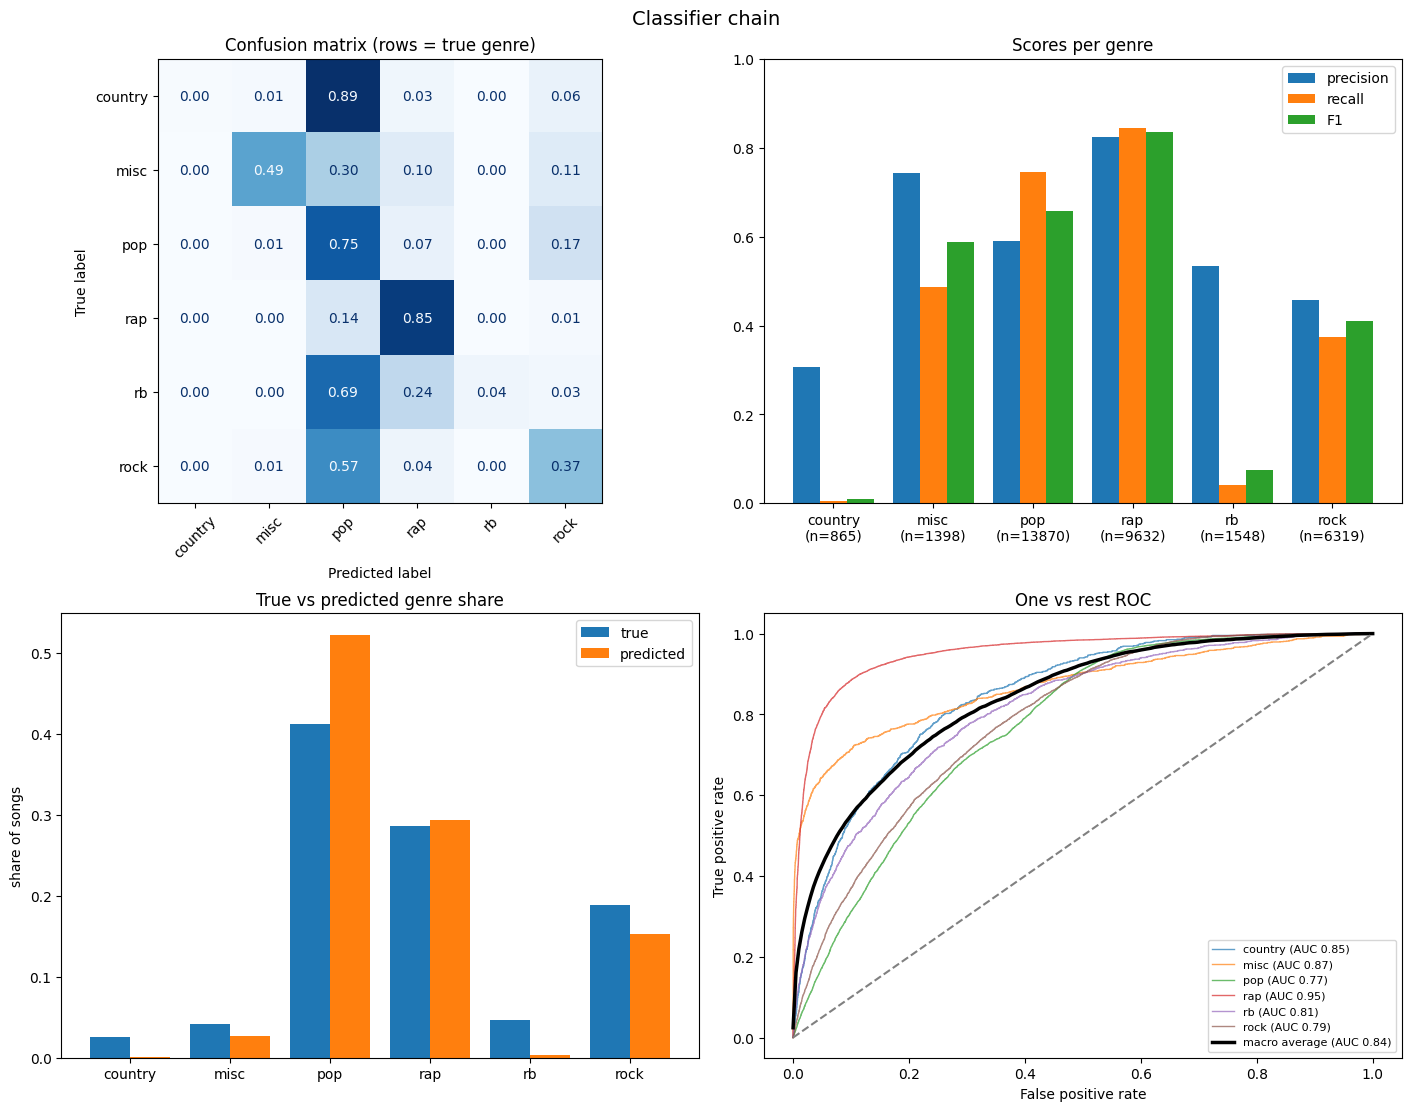

In [105]:
diagnose_runs(y_val, {key: multi_runs[key] for key in ("OneVsRest", "Chain")}, genres, labels)

### Comparison of the Three Forests

The three random forests side by side, followed by the F1 score per genre. A strategy can raise the macro F1 by helping the small genres while costing accuracy on the big ones, which the per genre table shows.

strategy,train_accuracy,accuracy,macro_f1,weighted_f1,fit_seconds
str,f64,f64,f64,f64,f64
"""Multiclass""",0.913,0.629,0.452,0.613,58.9
"""Classifier chain""",0.94,0.642,0.43,0.616,401.5
"""One-vs-rest""",0.955,0.658,0.423,0.617,393.1


strategy,country,misc,pop,rap,rb,rock
str,f64,f64,f64,f64,f64,f64
"""Multiclass""",0.054,0.55,0.65,0.822,0.242,0.394
"""Classifier chain""",0.009,0.588,0.659,0.835,0.076,0.411
"""One-vs-rest""",0.005,0.594,0.693,0.835,0.072,0.34


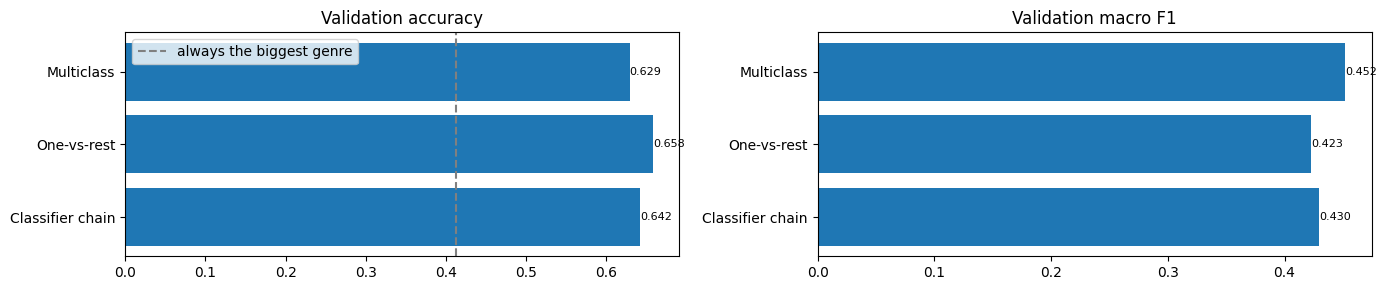

In [106]:
multi_scores, multi_f1 = compare(y_val, multi_runs, genres, labels, key_names=("strategy",))

Interestingly enough, the rankings for accuracy and macro F1 are exactly flipped: one-vs-rest wins on accuracy (0.637) but comes last on macro F1, the plain multiclass forest wins on macro F1 (0.445) but comes last on accuracy, and the chain is just kinda mid either way. The per genre table shows why: the binary forests get a bit better at pop and rap, the big genres, and pay for it by almost completely giving up on country and rb (F1 of 0.02 to 0.09). Since macro F1 is the main metric, the plain multiclass forest stays, and the binary variants go back on the shelf.

## Tuning the Random Forest with Hyperband

The settings of the random forest above were picked by hand. This section searches over four of them with **Hyperband** (Li et al., 2017), a search that does not train every candidate to the end. It starts many random configurations with few trees, keeps only the best `1/ETA` of them, gives the survivors `ETA` times as many trees, and repeats. Bad configurations are dropped after a cheap look, and the budget goes to the promising ones. Hyperband runs this halving several times (*brackets*), each starting with a different trade-off between the number of configurations and the number of trees, because a short trial can be misleading. scikit-learn only has the halving step itself (`HalvingRandomSearchCV`), so the loop is written out in `hyperband` (`utils/funcs.py`). It works for any model: it is given a function that builds the model for a configuration and a budget, and the name of the parameter that the budget sets (`n_estimators` here, `max_iter` for the boosting model later).

**What is searched.** Everything else follows `make_models` (`max_features="sqrt"`, class weights from `BALANCED`):

| Parameter | Values | Meaning |
|---|---|---|
| `bootstrap` (+ `oob_score`) | `True`, `False` | `True`: every tree is trained on a bootstrap sample and the songs left out give a free *out-of-bag* score (`oob_score=True`). `False`: every tree sees all songs. |
| `min_impurity_decrease` | 0, 1e-6, 1e-5, 1e-4, 1e-3 | a split must lower the impurity by at least this much (scaled by the share of songs in the node), which stops weak splits |
| `min_samples_leaf` | 1, 5, 10, 20, 50, 100, 200 | the fewest songs in a leaf, the main brake on memorising songs |
| `criterion` | `gini`, `entropy` | the split quality measure (`log_loss` is the same as `entropy`) |

`min_impurity_decrease` and `min_samples_leaf` both limit how deep the trees grow, so they interact: a large value of one can make the other irrelevant.

**The budget** is the number of trees, up to 300. With `ETA = 2` (only the best half survives a round) and at least 30 trees there are four brackets, starting with 8 configurations at 38 trees, 6 at 75, 4 at 150 and 4 at 300 (22 random configurations in total). A forest that survives a round keeps its trees (`warm_start`) and only grows the new ones, so the whole search costs about 3700 trees, roughly 12 forests of 300 trees. Expect on the order of 10 to 20 minutes, depending on the number of cores, since forests with `min_samples_leaf=1` grow much deeper trees.

**How a configuration is scored.** The search uses a stratified 25% holdout of the *training* songs and the **macro F1** on it, so the shared validation set plays no part in the choice. The validation songs are used once at the end, for the best configuration only. The out-of-bag accuracy is logged next to the holdout accuracy to see whether it could replace a holdout.

**Limits.** Hyperband assumes that a configuration that looks good with 38 trees is also good with 300, which can favour settings that work well for small forests. The holdout is a single split, so small differences are noise. The holdout score of the best configuration is optimistic, because it was chosen for being the best on that holdout.

`TUNE = False` loads the saved log (`models/classic/rf_hyperband_log.csv`) instead of searching again. The search space and the budget (`search_space_rf`, `R`, `ETA`, `MIN_TREES`) can be changed in the next cell.

In [ ]:
TUNE = False   # False: load the saved search log instead of searching again

# tuning split: 25% of the training songs, so the shared validation set stays untouched
X_fit, X_hold, y_fit, y_hold = train_test_split(X_tr, y_train, test_size=0.25, stratify=y_train, random_state=SEED)

R = 300          # the most trees a forest can get (the resource)
ETA = 2           # after every rung only the best 1/ETA of the forests survive and get ETA times more trees
MIN_TREES = 30    # the fewest trees that are worth evaluating

search_space_rf = {
    "bootstrap": [True, False],                    # True also switches on the out-of-bag score
    "min_impurity_decrease": [0.0, 1e-6, 1e-5, 1e-4, 1e-3],
    "min_samples_leaf": [1, 5, 10, 20, 50, 100, 200],
    "criterion": ["gini", "log_loss"],
}

log_path_rf = classic_dir / "rf_hyperband_log.csv"
if TUNE:
    hb_log_rf = hyperband(lambda config, n: make_forest(config, n, SEED, BALANCED), search_space_rf,
                          X_fit, y_fit, X_hold, y_hold, max_budget=R, eta=ETA, min_budget=MIN_TREES, seed=SEED,
                          budget_param="n_estimators", budget_name="trees", extra=forest_oob)
    classic_dir.mkdir(parents=True, exist_ok=True)
    hb_log_rf.write_csv(log_path_rf)
else:
    hb_log_rf = pl.read_csv(log_path_rf)

print(f"{hb_log_rf['config_id'].n_unique()} configurations, {hb_log_rf.height} evaluations, "
      f"{hb_log_rf['fit_seconds'].sum() / 60:.1f} minutes of fitting")

22 configurations, 35 evaluations, 12.6 minutes of fitting


### Results of the Search

`plot_hyperband` (`utils/funcs.py`) draws the whole search as one matrix, with one row and one column per parameter:

- **The finalists** (table above the figure) are the forests that reached the full 300 trees, best macro F1 first.
- **The pairwise heatmaps** (below the diagonal) cover every pair of parameters. A cell is colored by the **best macro F1** that any configuration with that pair of values reached, and `n` is the number of configurations behind it. All heatmaps share one color scale, so a bright "hot zone" is directly comparable across panels and shows where two parameters work well together. Gray cells (`–`) were never sampled. With only 22 random configurations most cells rest on one or two configurations, so look for bright regions, not single bright cells.
- **The diagonal** shows the best macro F1 per value of a single parameter.
- **The gold outline** marks the values of the best configuration at the full budget in every panel.
- **Rank consistency** (top right) checks the core assumption of Hyperband, that a configuration that looks good with few trees is also good with many. For every step between two budgets it plots the score of every promoted configuration before and after the step, together with the Spearman rank correlation ρ. A high ρ means the halving kept the right configurations. Only the survivors are promoted, so every step covers just the top of the previous round, which lowers ρ. With only a few points per step, ρ is a rough guide.

**Which evaluations the heatmaps use** is set with `HEATMAP_BUDGET`:
- `None` uses every evaluation, the best that a pair ever reached. This favours values that survived to large budgets, which is exactly the question of where the winners came from.
- `"min"` uses only the smallest budget, a like-for-like comparison. Only the configurations of the first bracket start there.
- A number, e.g. `75`, uses only the evaluations at that budget (38, 75, 150 or 300 trees here).

config_id,bracket,bootstrap,min_impurity_decrease,min_samples_leaf,criterion,macro_f1,accuracy,oob_accuracy
i64,i64,bool,f64,i64,str,f64,f64,f64
17,1,false,0.0,10,"""log_loss""",0.456,0.567,null
7,3,false,0.0,10,"""log_loss""",0.455,0.565,null
14,1,false,0.0,5,"""gini""",0.455,0.625,null
20,0,true,0.0,5,"""log_loss""",0.449,0.626,0.623
12,2,true,0.0,20,"""gini""",0.407,0.477,0.476
18,0,false,0.0,1,"""gini""",0.399,0.654,null
19,0,false,0.0,100,"""gini""",0.373,0.433,null
21,0,false,0.001,50,"""log_loss""",0.344,0.402,null


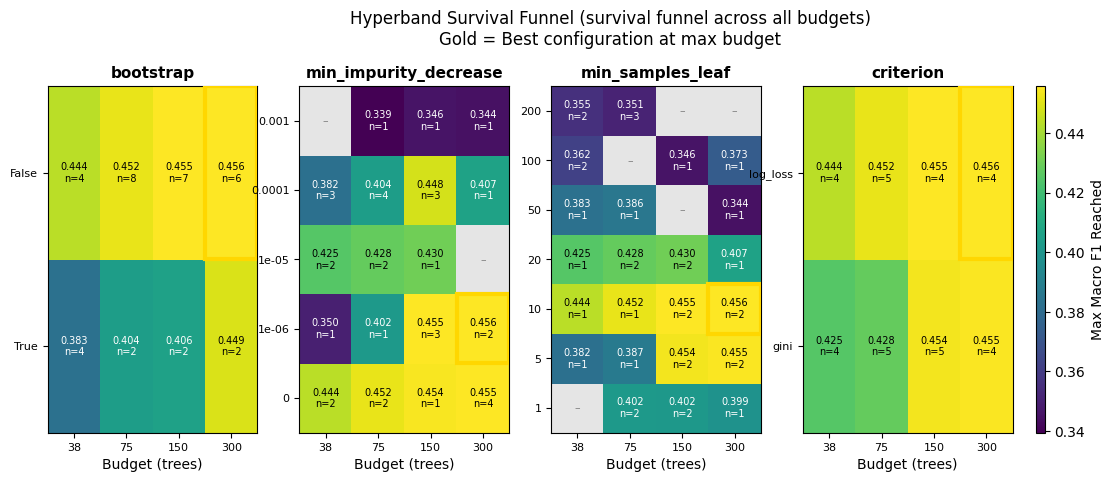

In [79]:
param_names_rf = list(search_space_rf)
HEATMAP_BUDGET = None   # None: every evaluation (best ever reached), "min": only the smallest budget, or e.g. 75

# the forests that survived to the full number of trees, best first
finalists_rf = hb_log_rf.filter(pl.col("trees") == R).sort("macro_f1", descending=True)
display(finalists_rf.select("config_id", "bracket", *param_names_rf, "macro_f1", "accuracy", "oob_accuracy")
        .with_columns(pl.col(pl.Float64).round(3)).head(10))

plot_hyperband(hb_log_rf, search_space_rf, budget_name="trees", budget=HEATMAP_BUDGET)

### The Tuned Forest on the Validation Songs

The best finalist is trained again on **all** training songs (the search only used 75% of them) with 300 trees, next to the forest with the current settings of `make_models`, and both are scored on the validation songs. This is the first time the validation songs are used, so this comparison is not biased by the search. Both forests are single runs with the same seed, so treat a macro F1 difference of a point or two with caution: it was not checked against other seeds.

In [80]:
best_config = finalists_rf.select(param_names_rf).row(0, named=True)
print("best configuration:", best_config)

# the forest with the current settings and the tuned one, both on all training songs, scored on the validation songs
rf_reg = make_models(SEED, BALANCED)["RandomForest"]
rf_tuned = make_forest(best_config, R, SEED, BALANCED).set_params(warm_start=False)

final_runs = {
    "Current settings": fit_run(rf_reg, X_tr, y_train, X_v, genres,
                                name="Current settings"),
    "Tuned by Hyperband": fit_run(rf_tuned, X_tr, y_train, X_v, genres, 
                                  name="Tuned by Hyperband")
                }

best configuration: {'bootstrap': False, 'min_impurity_decrease': 1e-06, 'min_samples_leaf': 10, 'criterion': 'log_loss'}
Current settings                         fitted in   58.1s
Tuned by Hyperband                       fitted in   92.0s


train accuracy: 0.913
val accuracy:   0.629  (always guessing the biggest genre: 0.412)
macro F1:       0.452
weighted F1:    0.613
              precision    recall  f1-score   support

     country       0.29      0.03      0.05       865
        misc       0.53      0.57      0.55      1398
         pop       0.61      0.69      0.65     13870
         rap       0.80      0.85      0.82      9632
          rb       0.30      0.20      0.24      1548
        rock       0.45      0.35      0.39      6319

    accuracy                           0.63     33632
   macro avg       0.50      0.45      0.45     33632
weighted avg       0.61      0.63      0.61     33632



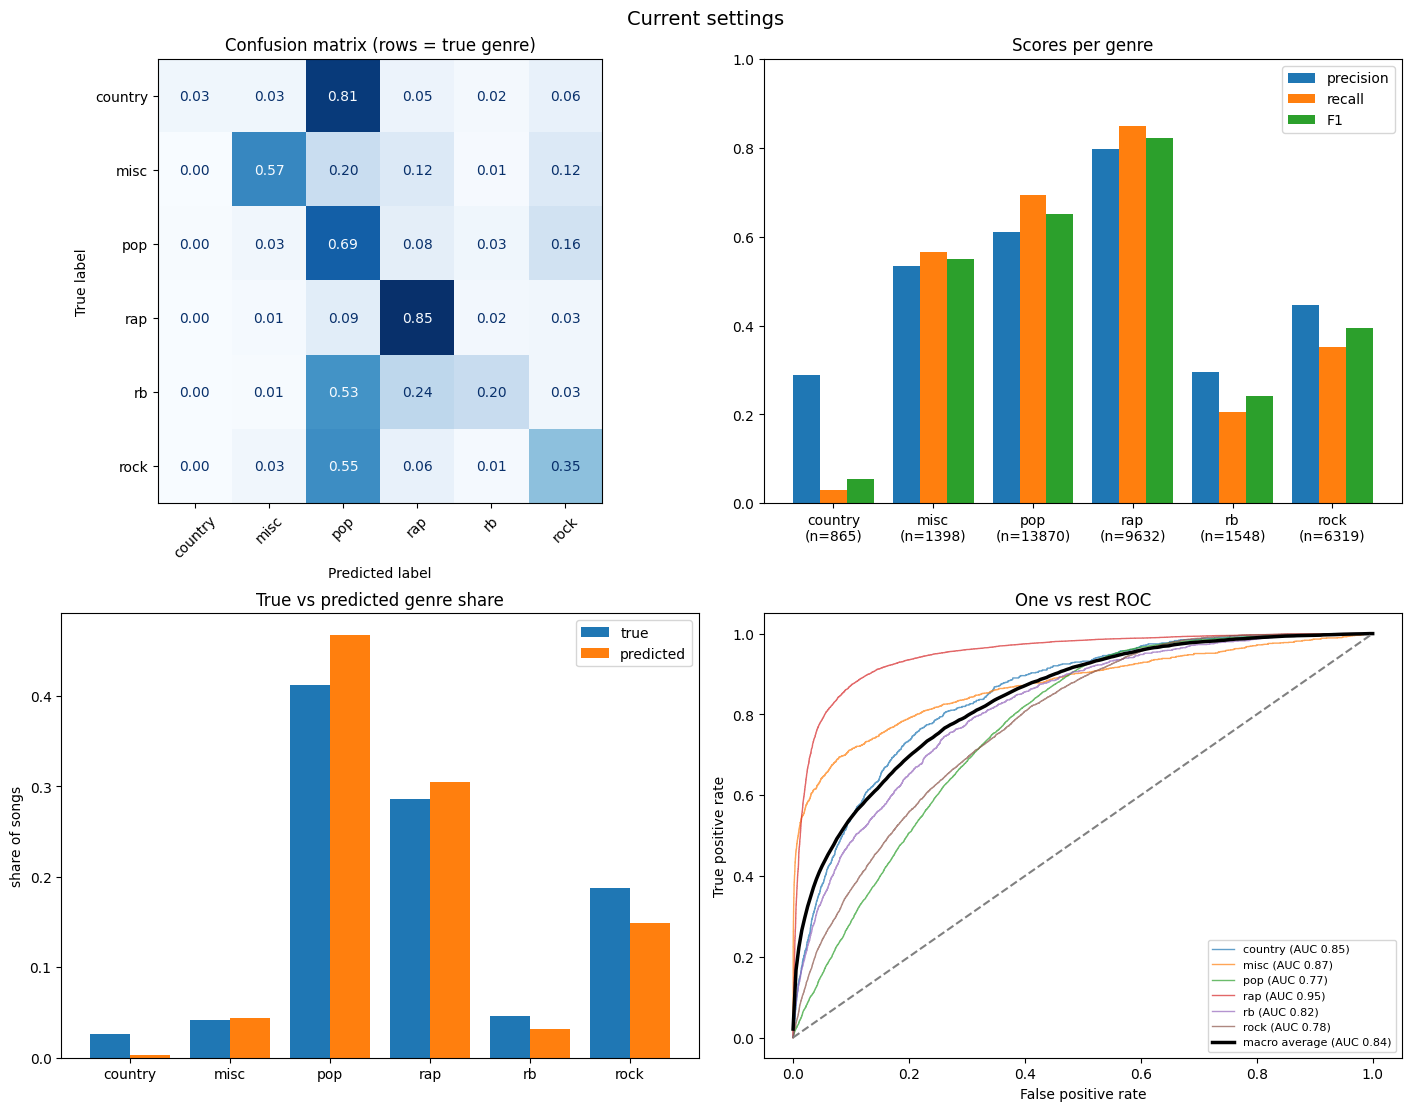

train accuracy: 0.813
val accuracy:   0.568  (always guessing the biggest genre: 0.412)
macro F1:       0.463
weighted F1:    0.574
              precision    recall  f1-score   support

     country       0.23      0.22      0.22       865
        misc       0.42      0.61      0.50      1398
         pop       0.65      0.45      0.53     13870
         rap       0.80      0.83      0.81      9632
          rb       0.20      0.40      0.27      1548
        rock       0.40      0.50      0.44      6319

    accuracy                           0.57     33632
   macro avg       0.45      0.50      0.46     33632
weighted avg       0.60      0.57      0.57     33632



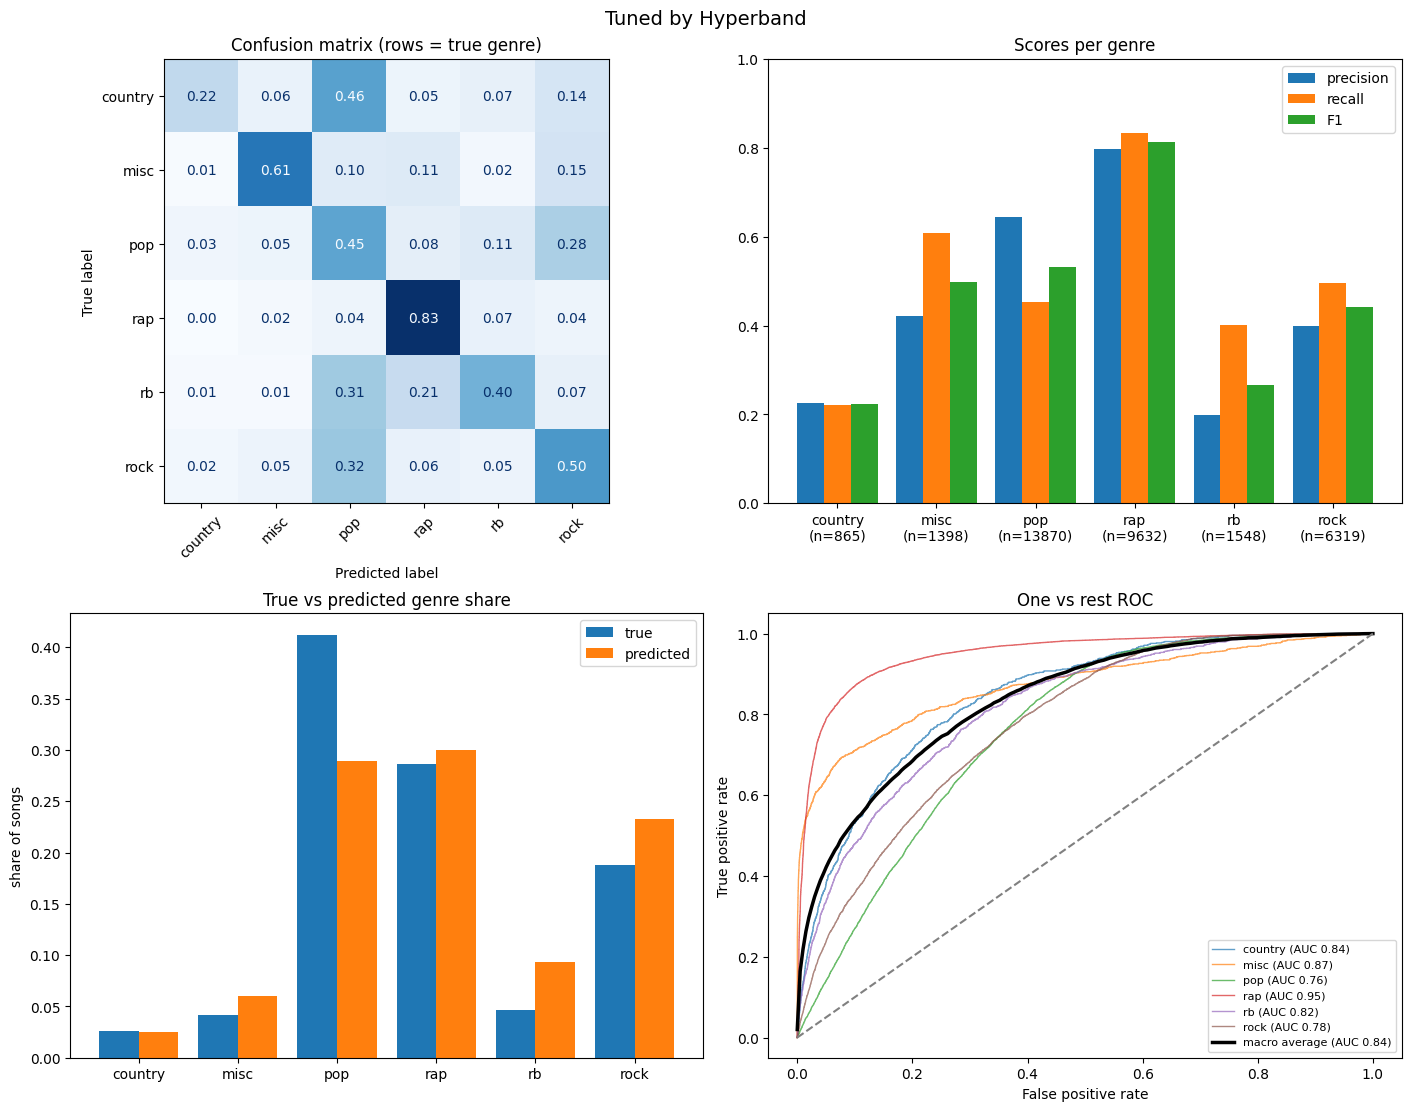

In [81]:
diagnose_runs(y_val, final_runs, genres, labels)

Hyperband turns the forest from a pop fanboy into something a little more open-minded. The tuned forest predicts pop far less often (pop recall drops from 0.69 to 0.45) and in return finally notices country, whose F1 goes from 0.05 to 0.22. Accuracy pays for it (0.629 to 0.568), macro F1 gains about one point (0.452 to 0.463), and the training accuracy drops from 0.913 to 0.813, so the tuned forest memorises less. One point of macro F1 from a single seed is within the noise mentioned above, so this is a nudge, not a breakthrough.

## Tuning Gradient Boosting with Hyperband

The forest has had its fun, so now gradient boosting, the narrow winner of the first comparison, gets the same treatment, to see whether tuning helps it as well. `hyperband` works for any model: it only needs a function that builds a model for a configuration and a budget, here `make_hgb` with the number of boosting iterations (`max_iter`) as the budget (the forest used the number of trees). Early stopping is switched off in the search, so the budget alone decides how long a model boosts, and a model that survives a round continues from its trees (`warm_start`).

**What is searched.** `learning_rate`, `l2_regularization`, `min_samples_leaf` and `max_depth` (the budget `max_iter` is not part of the space). The tuning split is the one of the forest, so the validation songs are again only used at the end. The search uses 300 iterations, ETA 3 and at least 10 iterations, so the same four brackets and about 4000 iterations in total.

**The final comparison** scores two gradient boosting models on the validation songs, both trained on all training songs:

- **Default:** the model of `make_models` (up to 300 iterations, stops early).
- **Tuned by Hyperband:** the best finalist with 300 iterations, without early stopping.
Boosting on the 1025 features is slow, the search costs about as much as 13 models with 300 iterations. `TUNE_GB = False` loads the saved log (`models/classic/gb_hyperband_log.csv`).

In [ ]:
TUNE_GB = False   # False: load the saved search log instead of searching again

R_GB = 300           # the most boosting iterations a model can get (the resource)
ETA_GB = 3           # after every rung only the best 1/ETA survive and get ETA times more iterations
MIN_ITER = 10        # the fewest iterations that are worth evaluating

# max_iter is the budget of the search, so it is not part of the space
search_space_gb = {
    "learning_rate": [0.01, 0.05, 0.1, 0.2, 0.3],
    "l2_regularization": [0.0, 0.01, 0.1, 0.2, 0.5],
    "min_samples_leaf": [10, 20, 50, 100, 200],
    "max_depth": [2, 3, 5, 7, 9, 11],
}

# same tuning split as the forest (X_fit, X_hold, y_fit, y_hold)
log_path_gb = classic_dir / "gb_hyperband_log.csv"
if TUNE_GB:
    hb_log_gb = hyperband(lambda config, n: make_hgb(config, n, SEED, BALANCED), search_space_gb,
                          X_fit, y_fit, X_hold, y_hold, max_budget=R_GB, eta=ETA_GB, min_budget=MIN_ITER, seed=SEED,
                          budget_param="max_iter", budget_name="iterations")
    classic_dir.mkdir(parents=True, exist_ok=True)
    hb_log_gb.write_csv(log_path_gb)
else:
    hb_log_gb = pl.read_csv(log_path_gb)

print(f"{hb_log_gb['config_id'].n_unique()} configurations, {hb_log_gb.height} evaluations, "
      f"{hb_log_gb['fit_seconds'].sum() / 60:.1f} minutes of fitting")

49 configurations, 69 evaluations, 53.4 minutes of fitting


### Results of the Search

The same overview as for the forest, with boosting iterations as the budget (11, 33, 100 or 300 for `HEATMAP_BUDGET_GB`).

config_id,bracket,learning_rate,l2_regularization,min_samples_leaf,max_depth,macro_f1,accuracy
i64,i64,f64,f64,i64,i64,f64,f64
47,0,0.2,0.2,50,9,0.487,0.613
44,1,0.2,0.5,50,9,0.484,0.611
8,3,0.3,0.1,200,11,0.484,0.615
45,0,0.3,0.01,100,7,0.479,0.605
39,1,0.05,0.1,20,11,0.477,0.564
33,2,0.3,0.5,50,11,0.476,0.617
48,0,0.3,0.2,20,2,0.438,0.513
46,0,0.2,0.5,50,2,0.438,0.508


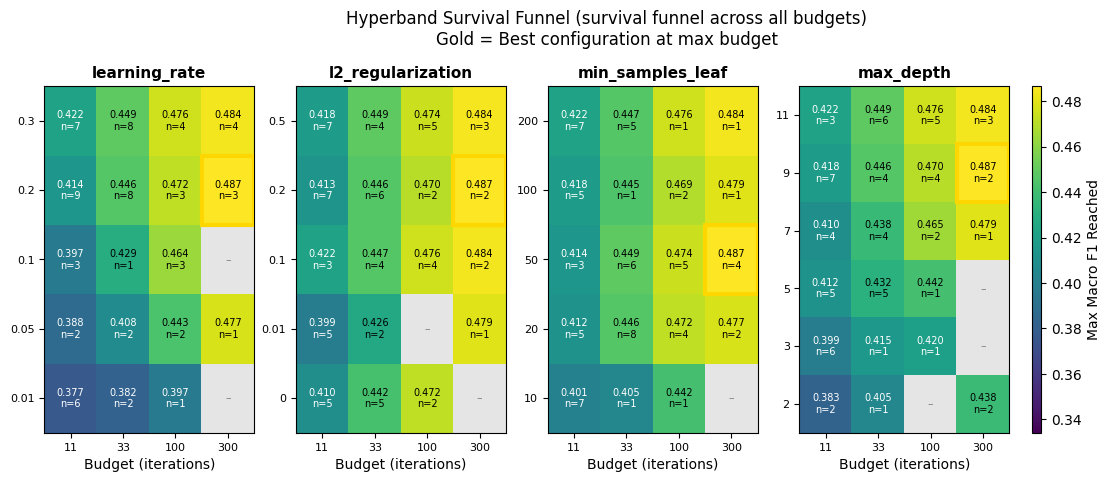

In [49]:
param_names_gb = list(search_space_gb)
HEATMAP_BUDGET_GB = None   # None: every evaluation (best ever reached), "min": only the smallest budget, or e.g. 33

# the models that survived to the full number of iterations, best first
finalists_gb = hb_log_gb.filter(pl.col("iterations") == R_GB).sort("macro_f1", descending=True)
display(finalists_gb.select("config_id", "bracket", *param_names_gb, "macro_f1", "accuracy")
        .with_columns(pl.col(pl.Float64).round(3)).head(10))

plot_hyperband(hb_log_gb, search_space_gb, budget_name="iterations", budget=HEATMAP_BUDGET_GB)

### The Tuned Model on the Validation Songs

As for the forest, the best finalist is trained again on all training songs and scored on the validation songs, next to the model of `make_models`.

In [84]:
best_config_gb = finalists_gb.select(param_names_gb).row(0, named=True)
print("best configuration:", best_config_gb)

gb_reg = make_models(SEED, BALANCED)["HistGradientBoosting"]
gb_tuned = make_hgb(best_config_gb, R_GB, SEED, BALANCED).set_params(warm_start=False)

final_gb_runs = {
    "Default": fit_run(gb_reg, X_tr, y_train, X_v, genres, name="Default"),
    "Tuned by Hyperband": fit_run(gb_tuned, X_tr, y_train, X_v, genres, name="Tuned by Hyperband")
                }

best configuration: {'learning_rate': 0.2, 'l2_regularization': 0.2, 'min_samples_leaf': 50, 'max_depth': 9}
Default                                  fitted in  186.9s
Tuned by Hyperband                       fitted in  288.5s


train accuracy: 0.600
val accuracy:   0.528  (always guessing the biggest genre: 0.412)
macro F1:       0.457
weighted F1:    0.543
              precision    recall  f1-score   support

     country       0.15      0.57      0.24       865
        misc       0.40      0.64      0.49      1398
         pop       0.66      0.32      0.43     13870
         rap       0.87      0.81      0.84      9632
          rb       0.19      0.53      0.28      1548
        rock       0.42      0.53      0.47      6319

    accuracy                           0.53     33632
   macro avg       0.45      0.57      0.46     33632
weighted avg       0.63      0.53      0.54     33632



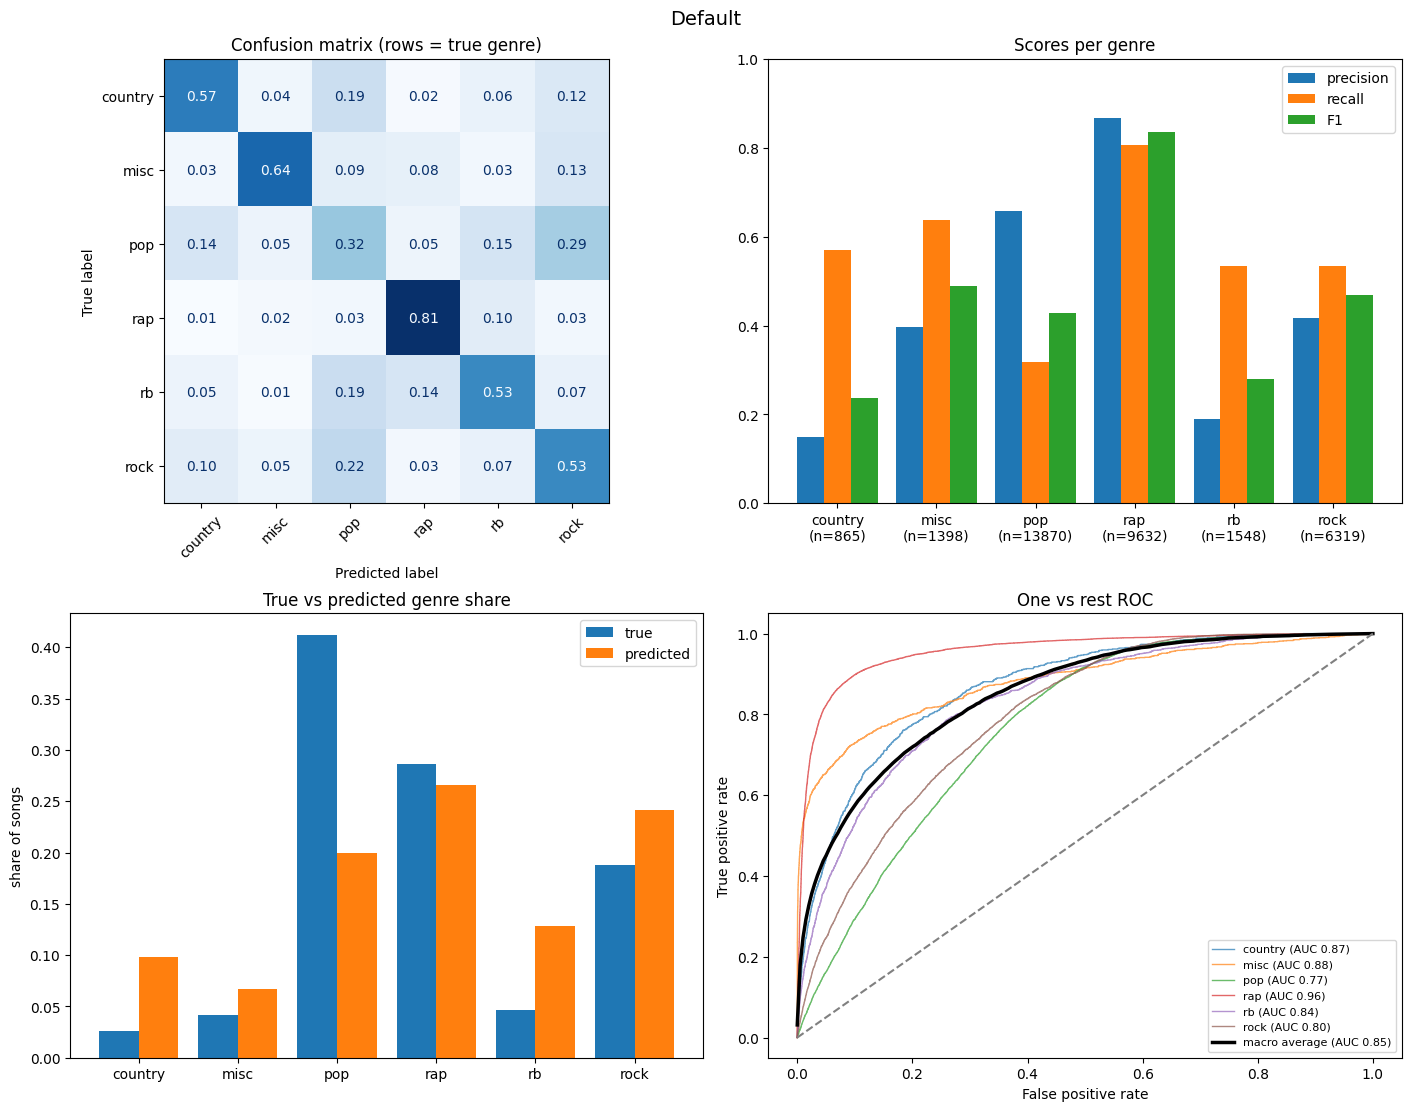

train accuracy: 0.886
val accuracy:   0.602  (always guessing the biggest genre: 0.412)
macro F1:       0.492
weighted F1:    0.606
              precision    recall  f1-score   support

     country       0.25      0.24      0.25       865
        misc       0.57      0.56      0.57      1398
         pop       0.62      0.54      0.58     13870
         rap       0.84      0.85      0.85      9632
          rb       0.25      0.30      0.27      1548
        rock       0.40      0.49      0.44      6319

    accuracy                           0.60     33632
   macro avg       0.49      0.50      0.49     33632
weighted avg       0.61      0.60      0.61     33632



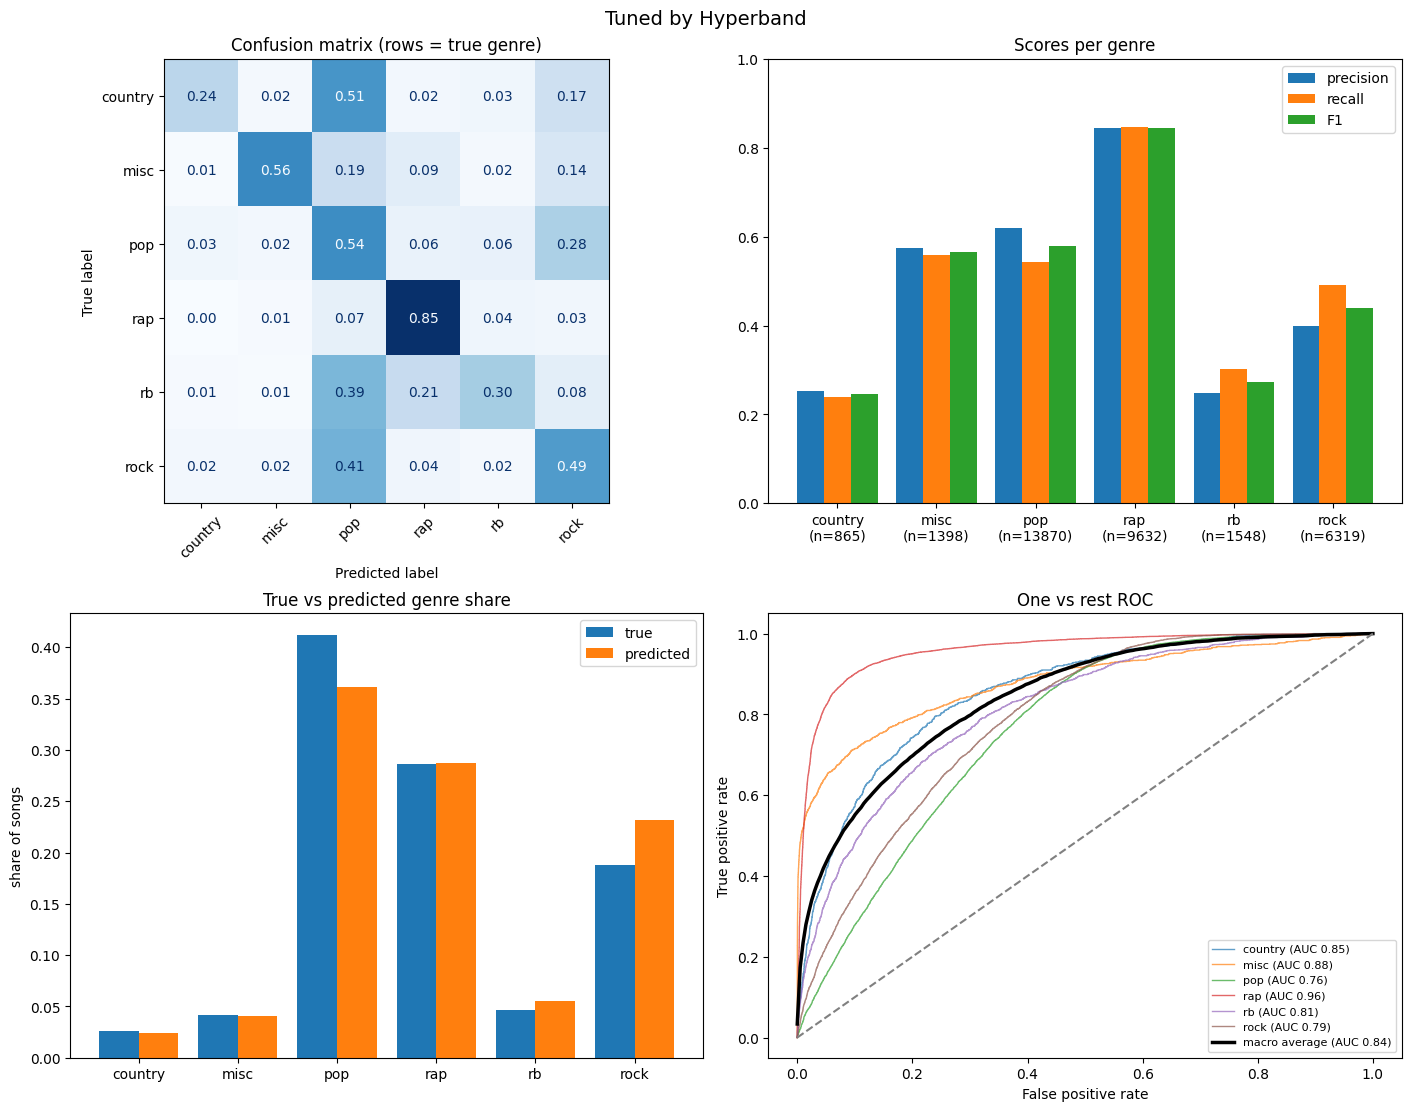

In [85]:
diagnose_runs(y_val, final_gb_runs, genres, labels)

Gradient boosting actually earns its training time. Unlike the forest, tuning improves both scores at once: accuracy goes from 0.528 to 0.602 and macro F1 from 0.457 to 0.492, mostly because the untuned model drastically under predicted pop (pop recall 0.32) and the tuned one does not (0.54). The price is a larger gap between training and validation accuracy (0.886 vs 0.602), so the tuned model fits the training songs much more closely.

## Final Comparison

All four candidates side by side: the random forest and gradient boosting, each with the settings of `make_models` and tuned by Hyperband. All of them are trained on all training songs with the `GloVe + TF-IDF` features and scored on the same validation songs.

model,train_accuracy,accuracy,macro_f1,weighted_f1,fit_seconds
str,f64,f64,f64,f64,f64
"""GB tuned""",0.886,0.602,0.492,0.606,288.5
"""RF tuned""",0.813,0.568,0.463,0.574,92.0
"""GB untuned""",0.6,0.528,0.457,0.543,186.9
"""RF untuned""",0.913,0.629,0.452,0.613,58.1


model,country,misc,pop,rap,rb,rock
str,f64,f64,f64,f64,f64,f64
"""GB tuned""",0.246,0.566,0.579,0.846,0.273,0.441
"""RF tuned""",0.224,0.499,0.532,0.814,0.266,0.442
"""GB untuned""",0.237,0.488,0.429,0.835,0.281,0.468
"""RF untuned""",0.054,0.55,0.65,0.822,0.242,0.394


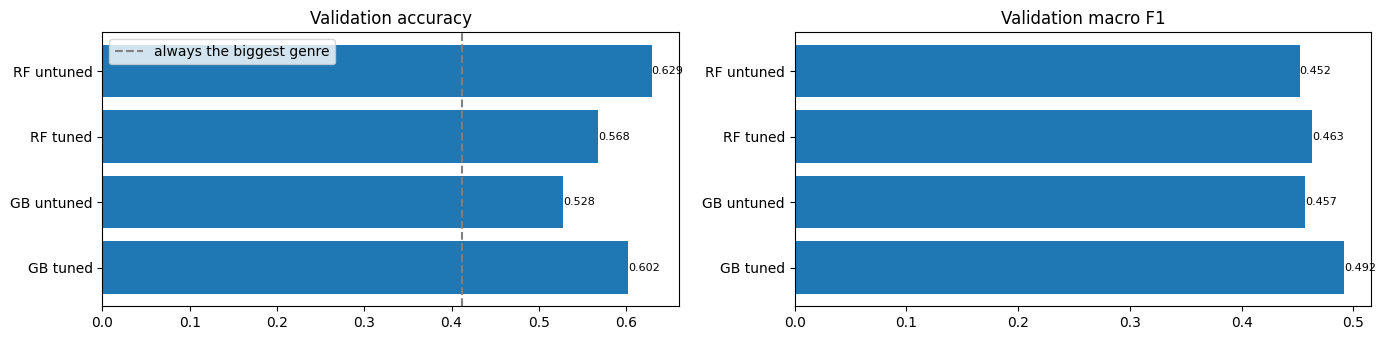

In [86]:
all_runs = {
    "RF untuned":        final_runs["Current settings"],
    "RF tuned":          final_runs["Tuned by Hyperband"],
    "GB untuned":        final_gb_runs["Default"],
    "GB tuned":          final_gb_runs["Tuned by Hyperband"],
}
all_scores, all_f1 = compare(y_val, all_runs, genres, key_names=("model",))

And the winner is tuned gradient boosting, with the best macro F1 (0.492) and the second best accuracy. The untuned forest still has the highest accuracy (0.629), but also the lowest macro F1, so most of that accuracy comes from betting on pop. Turns out my laptop had to be built for all that after all.

## Test Predictions

The tuned gradient boosting model, the winner of the final comparison, predicts the genres of the test songs. It is the model fitted above on the training songs only, and the validation songs are not added to its training data. The test features come from the same preprocessing (`data-Classic/test_glove_tfidf.parquet`) and are put in the same column order as the training features. The submission is checked against `sample_submission.csv` and written to `models/classic/submission_gb_tuned.csv`.

In [68]:
test = pl.read_parquet(classic_dir / "test_glove_tfidf.parquet")
X_test = test.select(both_cols).to_numpy().astype(np.float32)   # same columns and order as the training features

In [ ]:
test_ids = pl.read_csv(data_dir / "test.csv", columns=["id"])["id"]
assert len(test_ids) == X_test.shape[0]          # 33742

pred_test = gb_tuned.classes_[gb_tuned.predict_proba(X_test).argmax(axis=1)]

submission = pl.DataFrame({"id": test_ids, "tag": pred_test})

# the same checks the transformer notebook uses
sample = pl.read_csv(data_dir / "test.csv")
assert submission.columns == sample.columns
assert submission["id"].n_unique() == len(submission) == len(sample)
assert set(submission["id"]) == set(sample["id"])
assert set(submission["tag"]) <= set(genres)

submission.write_csv(classic_dir / "submission_gb_tuned.csv")